In [3]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [4]:
pip install pandas numpy scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

In [6]:
pip install matplotlib seaborn shap

Note: you may need to restart the kernel to use updated packages.


In [7]:
# ============================================================
# CELL 1 - IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.preprocessing import MinMaxScaler

from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    RandomForestRegressor,
    VotingRegressor,
    StackingRegressor
)

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

import warnings

warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [8]:
# ============================================================
# CELL 2 - LOAD DATASET
# ============================================================

FILE_PATH = "data.csv"

df = pd.read_csv(FILE_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Shape: (144, 9)


,Sr. No.,Time (min),Feed concentration (mg/L),Treated flowrate (L/h),Concentrated flowrate (L/h),Applied potential (V),SR (%),EC (kWh/kg),η (%)
0,1,5,5000,90,60,65.0,71.10,0.77,59.72
1,2,10,5000,90,60,65.0,67.84,0.88,52.02
2,3,15,5000,90,60,65.0,68.66,0.83,55.05
3,4,20,5000,90,60,65.0,68.86,0.79,57.84
4,5,5,5000,90,60,97.5,74.44,1.26,54.71


In [9]:
# ============================================================
# CELL 3 - DATASET INFORMATION
# ============================================================

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
for i, column in enumerate(df.columns):
    print(i, "->", column)

print("\nData types:")
display(df.dtypes)

Number of rows: 144
Number of columns: 9

Column names:
0 -> Sr. No.
1 -> Time (min)
2 -> Feed concentration (mg/L)
3 -> Treated flowrate (L/h)
4 -> Concentrated flowrate (L/h)
5 -> Applied potential (V)
6 -> SR (%)
7 -> EC (kWh/kg)
8 -> η (%)

Data types:


Sr. No.                          int64
Time (min)                       int64
Feed concentration (mg/L)        int64
Treated flowrate (L/h)           int64
Concentrated flowrate (L/h)      int64
Applied potential (V)          float64
SR (%)                         float64
EC (kWh/kg)                    float64
η (%)                          float64
dtype: object

In [10]:
# ============================================================
# CELL 4 - DATA QUALITY CHECK
# ============================================================

print("Missing values:")
display(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:


Sr. No.                        0
Time (min)                     0
Feed concentration (mg/L)      0
Treated flowrate (L/h)         0
Concentrated flowrate (L/h)    0
Applied potential (V)          0
SR (%)                         0
EC (kWh/kg)                    0
η (%)                          0
dtype: int64


Total missing values: 0

Duplicate rows:
0


In [11]:
# ============================================================
# CELL 5 - DEFINE FEATURES AND TARGETS
# ============================================================

feature_columns = [
    "Time (min)",
    "Feed concentration (mg/L)",
    "Treated flowrate (L/h)",
    "Concentrated flowrate (L/h)",
    "Applied potential (V)"
]

target_columns = [
    "SR (%)",
    "EC (kWh/kg)",
    "η (%)"
]

X = df[feature_columns].copy()
y = df[target_columns].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nInput variables:")
display(X.head())

print("\nOutput variables:")
display(y.head())

X shape: (144, 5)
y shape: (144, 3)

Input variables:


,Time (min),Feed concentration (mg/L),Treated flowrate (L/h),Concentrated flowrate (L/h),Applied potential (V)
0,5,5000,90,60,65.0
1,10,5000,90,60,65.0
2,15,5000,90,60,65.0
3,20,5000,90,60,65.0
4,5,5000,90,60,97.5



Output variables:


,SR (%),EC (kWh/kg),η (%)
0,71.10,0.77,59.72
1,67.84,0.88,52.02
2,68.66,0.83,55.05
3,68.86,0.79,57.84
4,74.44,1.26,54.71


In [12]:
# ============================================================
# CELL 6 - DESCRIPTIVE STATISTICS
# ============================================================

print("INPUT VARIABLES")
display(X.describe().T)

print("\nOUTPUT VARIABLES")
display(y.describe().T)

INPUT VARIABLES


,count,mean,std,min,25%,50%,75%,max
Time (min),144.0,12.5,5.609682,5.0,8.75,12.5,16.25,20.0
Feed concentration (mg/L),144.0,16250.0,9634.945139,5000.0,8750.00,15000.0,22500.00,30000.0
Treated flowrate (L/h),144.0,105.0,12.290197,90.0,90.00,105.0,120.00,120.0
Concentrated flowrate (L/h),144.0,45.0,12.290197,30.0,30.00,45.0,60.00,60.0
Applied potential (V),144.0,97.5,26.628761,65.0,65.00,97.5,130.00,130.0



OUTPUT VARIABLES


,count,mean,std,min,25%,50%,75%,max
SR (%),144.0,51.480694,16.690378,18.20,37.4025,54.250,64.705,75.26
EC (kWh/kg),144.0,2.012361,0.819913,0.77,1.3875,1.885,2.445,5.55
η (%),144.0,36.762292,10.936720,2.00,30.1350,34.760,42.220,64.82


In [13]:
# ============================================================
# CELL 7 - RANGE CHECK
# ============================================================

range_table = pd.DataFrame({
    "Minimum": X.min(),
    "Maximum": X.max(),
    "Mean": X.mean(),
    "Std": X.std()
})

display(range_table)

,Minimum,Maximum,Mean,Std
Time (min),5.0,20.0,12.5,5.609682
Feed concentration (mg/L),5000.0,30000.0,16250.0,9634.945139
Treated flowrate (L/h),90.0,120.0,105.0,12.290197
Concentrated flowrate (L/h),30.0,60.0,45.0,12.290197
Applied potential (V),65.0,130.0,97.5,26.628761


In [14]:
# ============================================================
# CELL 8 - PEARSON CORRELATION
# ============================================================

correlation_data = df[
    feature_columns + target_columns
]

correlation_matrix = correlation_data.corr(
    method="pearson"
)

display(correlation_matrix)

,Time (min),Feed concentration (mg/L),Treated flowrate (L/h),Concentrated flowrate (L/h),Applied potential (V),SR (%),EC (kWh/kg),η (%)
Time (min),1.000000e+00,3.181877e-16,7.207042e-17,-1.167541e-16,3.592433e-17,0.006296,-0.101335,0.113051
Feed concentration (mg/L),3.181877e-16,1.000000e+00,-1.228887e-15,-5.156170e-16,2.157659e-16,-0.777729,0.465466,-0.636010
Treated flowrate (L/h),7.207042e-17,-1.228887e-15,1.000000e+00,-1.000000e+00,-1.894781e-16,-0.407317,0.380258,-0.525847
Concentrated flowrate (L/h),-1.167541e-16,-5.156170e-16,-1.000000e+00,1.000000e+00,-1.093143e-17,0.407317,-0.380258,0.525847
Applied potential (V),3.592433e-17,2.157659e-16,-1.894781e-16,-1.093143e-17,1.000000e+00,0.348612,0.648614,0.079662
SR (%),6.296325e-03,-7.777291e-01,-4.073168e-01,4.073168e-01,3.486122e-01,1.000000,-0.354789,0.807900
EC (kWh/kg),-1.013347e-01,4.654662e-01,3.802579e-01,-3.802579e-01,6.486140e-01,-0.354789,1.000000,-0.615521
η (%),1.130508e-01,-6.360096e-01,-5.258472e-01,5.258472e-01,7.966177e-02,0.807900,-0.615521,1.000000


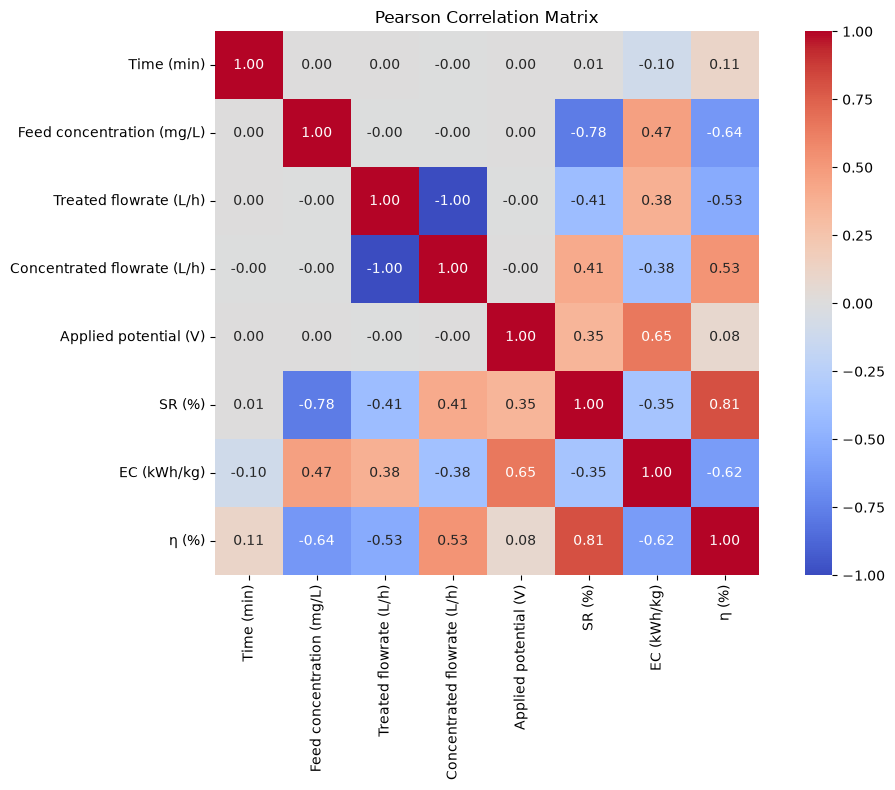

In [15]:
# ============================================================
# CELL 9 - PEARSON CORRELATION HEATMAP
# ============================================================

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Pearson Correlation Matrix")
plt.tight_layout()

plt.savefig(
    "Figure_5_Pearson_Correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
# ============================================================
# CELL 10 - TRAIN / TEST SPLIT
# ============================================================

RANDOM_STATE = 2

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 100
Testing samples: 44


In [17]:
# ============================================================
# CELL 11 - MIN-MAX NORMALIZATION
# ============================================================

X_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()

X_train_scaled = X_scaler.fit_transform(X_train)

X_test_scaled = X_scaler.transform(X_test)

y_train_scaled = y_scaler.fit_transform(y_train)

y_test_scaled = y_scaler.transform(y_test)

print("Normalization completed.")

Normalization completed.


In [18]:
# ============================================================
# CELL 12 - VERIFY NORMALIZATION
# ============================================================

print("X train min:")
print(X_train_scaled.min(axis=0))

print("\nX train max:")
print(X_train_scaled.max(axis=0))

print("\ny train min:")
print(y_train_scaled.min(axis=0))

print("\ny train max:")
print(y_train_scaled.max(axis=0))

X train min:
[0. 0. 0. 0. 0.]

X train max:
[1. 1. 1. 1. 1.]

y train min:
[0. 0. 0.]

y train max:
[1. 1. 1.]


In [19]:
# ============================================================
# CELL 13 - METRIC FUNCTION
# ============================================================

def calculate_metrics(y_true, y_pred):
    
    r2 = r2_score(y_true, y_pred)
    
    mse = mean_squared_error(
        y_true,
        y_pred
    )
    
    rmse = np.sqrt(mse)
    
    mae = mean_absolute_error(
        y_true,
        y_pred
    )
    
    return r2, mse, rmse, mae

In [20]:
# ============================================================
# CELL 14 - MODEL EVALUATION FUNCTION
# ============================================================

def evaluate_model(
    model_name,
    y_true,
    y_pred,
    target_names=target_columns
):
    
    results = []
    
    for i, target in enumerate(target_names):
        
        r2, mse, rmse, mae = calculate_metrics(
            y_true[:, i],
            y_pred[:, i]
        )
        
        results.append({
            "Model": model_name,
            "Target": target,
            "R2": r2,
            "MSE": mse,
            "RMSE": rmse,
            "MAE": mae
        })
    
    return pd.DataFrame(results)

In [21]:
# ============================================================
# CELL 15 - PAPER MLP BASELINE
# ============================================================

paper_neurons = {
    "SR (%)": 14,
    "EC (kWh/kg)": 33,
    "η (%)": 13
}

mlp_models = []
mlp_predictions = []

for i, target in enumerate(target_columns):
    
    model = MLPRegressor(
        hidden_layer_sizes=(
            paper_neurons[target],
        ),
        activation="tanh",
        solver="lbfgs",
        max_iter=2000,
        random_state=1
    )
    
    model.fit(
        X_train_scaled,
        y_train_scaled[:, i]
    )
    
    prediction = model.predict(
        X_test_scaled
    )
    
    mlp_models.append(model)
    mlp_predictions.append(prediction)

mlp_predictions = np.column_stack(
    mlp_predictions
)

print("Paper MLP trained.")

Paper MLP trained.


In [22]:
# ============================================================
# CELL 16 - DENORMALIZE MLP PREDICTIONS
# ============================================================

mlp_predictions_original = y_scaler.inverse_transform(
    mlp_predictions
)

y_test_original = y_test.values

print(
    mlp_predictions_original[:5]
)

[[74.0496694   1.27650957 60.09115351]
 [19.18263108  3.15490571 21.74847817]
 [30.39057617  2.44703887 27.32943851]
 [75.08592099  1.21533994 56.760961  ]
 [54.28461214  1.32537355 34.07635572]]


In [23]:
# ============================================================
# CELL 17 - PAPER MLP RESULTS
# ============================================================

paper_mlp_results = evaluate_model(
    "Paper MLP",
    y_test_original,
    mlp_predictions_original
)

display(
    paper_mlp_results
)

,Model,Target,R2,MSE,RMSE,MAE
0,Paper MLP,SR (%),0.966085,11.854922,3.443098,2.814214
1,Paper MLP,EC (kWh/kg),0.826287,0.071466,0.267331,0.203521
2,Paper MLP,η (%),0.814903,28.620971,5.349857,3.420389


In [24]:
# ============================================================
# CELL 18 - MLP HYPERPARAMETER SEARCH
# ============================================================

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

mlp_parameter_grid = {
    "hidden_layer_sizes": [
        (5,),
        (8,),
        (10,),
        (12,),
        (14,),
        (16,),
        (20,),
        (25,),
        (30,),
        (33,),
        (40,),
        (50,),
        (10, 5),
        (15, 5),
        (20, 10),
        (30, 10)
    ],
    
    "activation": [
        "tanh",
        "relu"
    ],
    
    "solver": [
        "lbfgs"
    ],
    
    "alpha": [
        0.00001,
        0.0001,
        0.001,
        0.01
    ],
    
    "max_iter": [
        2000
    ]
}

In [25]:
# ============================================================
# CELL 19 - OPTIMIZED MLP
# ============================================================

optimized_mlp_models = []
optimized_mlp_predictions = []

mlp_search_results = []

for i, target in enumerate(target_columns):
    
    print("\nOptimizing:", target)
    
    search = GridSearchCV(
        estimator=MLPRegressor(
            random_state=42
        ),
        
        param_grid=mlp_parameter_grid,
        
        scoring="r2",
        
        cv=cv,
        
        n_jobs=-1
    )
    
    search.fit(
        X_train_scaled,
        y_train_scaled[:, i]
    )
    
    print("Best parameters:")
    print(search.best_params_)
    
    print(
        "Best CV R²:",
        search.best_score_
    )
    
    optimized_model = search.best_estimator_
    
    prediction = optimized_model.predict(
        X_test_scaled
    )
    
    optimized_mlp_models.append(
        optimized_model
    )
    
    optimized_mlp_predictions.append(
        prediction
    )
    
    mlp_search_results.append({
        "Target": target,
        "Best CV R2": search.best_score_,
        "Best Parameters": search.best_params_
    })

optimized_mlp_predictions = np.column_stack(
    optimized_mlp_predictions
)


Optimizing: SR (%)
Best parameters:
{'activation': 'relu', 'alpha': 1e-05, 'hidden_layer_sizes': (20, 10), 'max_iter': 2000, 'solver': 'lbfgs'}
Best CV R²: 0.9252305475442777

Optimizing: EC (kWh/kg)
Best parameters:
{'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (20,), 'max_iter': 2000, 'solver': 'lbfgs'}
Best CV R²: 0.9032915689977212

Optimizing: η (%)
Best parameters:
{'activation': 'tanh', 'alpha': 1e-05, 'hidden_layer_sizes': (20, 10), 'max_iter': 2000, 'solver': 'lbfgs'}
Best CV R²: 0.8900659555718333


In [26]:
# ============================================================
# CELL 20 - OPTIMIZED MLP RESULTS
# ============================================================

optimized_mlp_predictions_original = (
    y_scaler.inverse_transform(
        optimized_mlp_predictions
    )
)

optimized_mlp_results = evaluate_model(
    "Optimized MLP",
    y_test_original,
    optimized_mlp_predictions_original
)

display(
    optimized_mlp_results
)

,Model,Target,R2,MSE,RMSE,MAE
0,Optimized MLP,SR (%),0.932187,23.704193,4.868695,3.364128
1,Optimized MLP,EC (kWh/kg),0.823938,0.072432,0.269133,0.188255
2,Optimized MLP,η (%),0.839171,24.868382,4.986821,3.037464


In [27]:
# ============================================================
# CELL 21 - RANDOM FOREST SEARCH
# ============================================================

rf_parameter_grid = {
    
    "n_estimators": [
        50,
        100,
        200,
        300,
        500
    ],
    
    "max_depth": [
        None,
        3,
        5,
        8,
        12,
        20
    ],
    
    "min_samples_split": [
        2,
        3,
        5,
        8
    ],
    
    "min_samples_leaf": [
        1,
        2,
        3,
        5
    ],
    
    "max_features": [
        0.7,
        1.0
    ]
}

In [28]:
# ============================================================
# CELL 22 - OPTIMIZED RANDOM FOREST
# ============================================================

optimized_rf_models = []
optimized_rf_predictions = []

for i, target in enumerate(target_columns):
    
    print("\nOptimizing RF:", target)
    
    search = RandomizedSearchCV(
        
        estimator=RandomForestRegressor(
            random_state=42,
            n_jobs=-1
        ),
        
        param_distributions=rf_parameter_grid,
        
        n_iter=40,
        
        scoring="r2",
        
        cv=cv,
        
        random_state=42,
        
        n_jobs=-1
    )
    
    search.fit(
        X_train_scaled,
        y_train_scaled[:, i]
    )
    
    print(
        "Best CV R²:",
        search.best_score_
    )
    
    print(
        "Best parameters:",
        search.best_params_
    )
    
    model = search.best_estimator_
    
    prediction = model.predict(
        X_test_scaled
    )
    
    optimized_rf_models.append(model)
    optimized_rf_predictions.append(prediction)

optimized_rf_predictions = np.column_stack(
    optimized_rf_predictions
)


Optimizing RF: SR (%)
Best CV R²: 0.9266682392158664
Best parameters: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 12}

Optimizing RF: EC (kWh/kg)
Best CV R²: 0.8758028345495366
Best parameters: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 12}

Optimizing RF: η (%)
Best CV R²: 0.851506546439374
Best parameters: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 12}


In [29]:
# ============================================================
# CELL 23 - OPTIMIZED RF RESULTS
# ============================================================

optimized_rf_predictions_original = (
    y_scaler.inverse_transform(
        optimized_rf_predictions
    )
)

optimized_rf_results = evaluate_model(
    "Optimized RF",
    y_test_original,
    optimized_rf_predictions_original
)

display(
    optimized_rf_results
)

,Model,Target,R2,MSE,RMSE,MAE
0,Optimized RF,SR (%),0.972571,9.587880,3.096430,2.626205
1,Optimized RF,EC (kWh/kg),0.841417,0.065242,0.255424,0.190073
2,Optimized RF,η (%),0.788123,32.761828,5.723795,3.681682


In [30]:
# ============================================================
# CELL 24 - EXTRA TREES
# ============================================================

extra_trees_models = []
extra_trees_predictions = []

for i, target in enumerate(target_columns):
    
    model = ExtraTreesRegressor(
        n_estimators=500,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    )
    
    model.fit(
        X_train_scaled,
        y_train_scaled[:, i]
    )
    
    prediction = model.predict(
        X_test_scaled
    )
    
    extra_trees_models.append(model)
    extra_trees_predictions.append(prediction)

extra_trees_predictions = np.column_stack(
    extra_trees_predictions
)

extra_trees_predictions_original = (
    y_scaler.inverse_transform(
        extra_trees_predictions
    )
)

extra_trees_results = evaluate_model(
    "Extra Trees",
    y_test_original,
    extra_trees_predictions_original
)

display(extra_trees_results)

,Model,Target,R2,MSE,RMSE,MAE
0,Extra Trees,SR (%),0.987967,4.206266,2.050918,1.517475
1,Extra Trees,EC (kWh/kg),0.903338,0.039767,0.199417,0.137708
2,Extra Trees,η (%),0.827315,26.701644,5.167363,3.134666


In [31]:
# ============================================================
# CELL 25 - GRADIENT BOOSTING
# ============================================================

gb_models = []
gb_predictions = []

for i, target in enumerate(target_columns):
    
    model = GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=3,
        min_samples_split=2,
        min_samples_leaf=2,
        loss="huber",
        random_state=42
    )
    
    model.fit(
        X_train_scaled,
        y_train_scaled[:, i]
    )
    
    prediction = model.predict(
        X_test_scaled
    )
    
    gb_models.append(model)
    gb_predictions.append(prediction)

gb_predictions = np.column_stack(
    gb_predictions
)

gb_predictions_original = (
    y_scaler.inverse_transform(
        gb_predictions
    )
)

gb_results = evaluate_model(
    "Gradient Boosting",
    y_test_original,
    gb_predictions_original
)

display(gb_results)

,Model,Target,R2,MSE,RMSE,MAE
0,Gradient Boosting,SR (%),0.930565,24.271045,4.926565,3.741919
1,Gradient Boosting,EC (kWh/kg),0.833694,0.068419,0.261570,0.199721
2,Gradient Boosting,η (%),0.707614,45.210569,6.723880,4.540683


In [32]:
# ============================================================
# CELL 26 - OPTIMIZED SVR
# ============================================================

svr_parameter_grid = {
    
    "kernel": [
        "linear",
        "poly",
        "rbf"
    ],
    
    "C": [
        0.01,
        0.1,
        1,
        10,
        50,
        100,
        500,
        1000
    ],
    
    "epsilon": [
        0.001,
        0.01,
        0.05,
        0.1,
        0.2
    ],
    
    "gamma": [
        "scale",
        "auto",
        0.001,
        0.01,
        0.1,
        1
    ]
}

In [33]:
# ============================================================
# CELL 27 - SVR SEARCH
# ============================================================

optimized_svr_models = []
optimized_svr_predictions = []

for i, target in enumerate(target_columns):
    
    print("\nOptimizing SVR:", target)
    
    search = RandomizedSearchCV(
        
        estimator=SVR(),
        
        param_distributions=svr_parameter_grid,
        
        n_iter=60,
        
        scoring="r2",
        
        cv=cv,
        
        random_state=42,
        
        n_jobs=-1
    )
    
    search.fit(
        X_train_scaled,
        y_train_scaled[:, i]
    )
    
    print(
        "Best CV R²:",
        search.best_score_
    )
    
    print(
        "Best parameters:",
        search.best_params_
    )
    
    model = search.best_estimator_
    
    prediction = model.predict(
        X_test_scaled
    )
    
    optimized_svr_models.append(model)
    optimized_svr_predictions.append(prediction)

optimized_svr_predictions = np.column_stack(
    optimized_svr_predictions
)

optimized_svr_predictions_original = (
    y_scaler.inverse_transform(
        optimized_svr_predictions
    )
)


Optimizing SVR: SR (%)
Best CV R²: 0.8801323182302685
Best parameters: {'kernel': 'rbf', 'gamma': 'auto', 'epsilon': 0.1, 'C': 10}

Optimizing SVR: EC (kWh/kg)
Best CV R²: 0.8214822992629941
Best parameters: {'kernel': 'rbf', 'gamma': 1, 'epsilon': 0.05, 'C': 10}

Optimizing SVR: η (%)
Best CV R²: 0.7267459498857872
Best parameters: {'kernel': 'rbf', 'gamma': 'auto', 'epsilon': 0.1, 'C': 10}


In [34]:
# ============================================================
# CELL 28 - SVR RESULTS
# ============================================================

optimized_svr_results = evaluate_model(
    "Optimized SVR",
    y_test_original,
    optimized_svr_predictions_original
)

display(
    optimized_svr_results
)

,Model,Target,R2,MSE,RMSE,MAE
0,Optimized SVR,SR (%),0.929497,24.644190,4.964291,4.015867
1,Optimized SVR,EC (kWh/kg),0.817512,0.075076,0.274000,0.218410
2,Optimized SVR,η (%),0.675144,50.231321,7.087406,5.445590


In [35]:
# ============================================================
# CELL 29 - MODEL COMPARISON
# ============================================================

all_results = pd.concat([
    
    paper_mlp_results,
    
    optimized_mlp_results,
    
    optimized_rf_results,
    
    extra_trees_results,
    
    gb_results,
    
    optimized_svr_results
    
], ignore_index=True)

display(
    all_results.sort_values(
        ["Target", "R2"],
        ascending=[True, False]
    )
)

,Model,Target,R2,MSE,RMSE,MAE
10,Extra Trees,EC (kWh/kg),0.903338,0.039767,0.199417,0.137708
7,Optimized RF,EC (kWh/kg),0.841417,0.065242,0.255424,0.190073
13,Gradient Boosting,EC (kWh/kg),0.833694,0.068419,0.261570,0.199721
1,Paper MLP,EC (kWh/kg),0.826287,0.071466,0.267331,0.203521
4,Optimized MLP,EC (kWh/kg),0.823938,0.072432,0.269133,0.188255
16,Optimized SVR,EC (kWh/kg),0.817512,0.075076,0.274000,0.218410
9,Extra Trees,SR (%),0.987967,4.206266,2.050918,1.517475
6,Optimized RF,SR (%),0.972571,9.587880,3.096430,2.626205
0,Paper MLP,SR (%),0.966085,11.854922,3.443098,2.814214
3,Optimized MLP,SR (%),0.932187,23.704193,4.868695,3.364128


In [36]:
# ============================================================
# CELL 30 - BEST MODEL PER TARGET
# ============================================================

best_models = (
    all_results
    .sort_values("R2", ascending=False)
    .groupby("Target")
    .first()
    .reset_index()
)

display(best_models)

,Target,Model,R2,MSE,RMSE,MAE
0,EC (kWh/kg),Extra Trees,0.903338,0.039767,0.199417,0.137708
1,SR (%),Extra Trees,0.987967,4.206266,2.050918,1.517475
2,η (%),Optimized MLP,0.839171,24.868382,4.986821,3.037464


In [37]:
# ============================================================
# CELL 31 - COMBINE ALL CURRENT RESULTS
# ============================================================

results_all = pd.concat([
    paper_mlp_results,
    optimized_mlp_results,
    optimized_rf_results,
    extra_trees_results,
    gb_results,
    optimized_svr_results
], ignore_index=True)

results_all = results_all.sort_values(
    ["Target", "R2"],
    ascending=[True, False]
).reset_index(drop=True)

display(results_all)

,Model,Target,R2,MSE,RMSE,MAE
0,Extra Trees,EC (kWh/kg),0.903338,0.039767,0.199417,0.137708
1,Optimized RF,EC (kWh/kg),0.841417,0.065242,0.255424,0.190073
2,Gradient Boosting,EC (kWh/kg),0.833694,0.068419,0.261570,0.199721
3,Paper MLP,EC (kWh/kg),0.826287,0.071466,0.267331,0.203521
4,Optimized MLP,EC (kWh/kg),0.823938,0.072432,0.269133,0.188255
5,Optimized SVR,EC (kWh/kg),0.817512,0.075076,0.274000,0.218410
6,Extra Trees,SR (%),0.987967,4.206266,2.050918,1.517475
7,Optimized RF,SR (%),0.972571,9.587880,3.096430,2.626205
8,Paper MLP,SR (%),0.966085,11.854922,3.443098,2.814214
9,Optimized MLP,SR (%),0.932187,23.704193,4.868695,3.364128


In [38]:
# ============================================================
# CELL 32 - PAPER VS OUR BEST
# ============================================================

paper_reference = pd.DataFrame({
    "Target": [
        "SR (%)",
        "EC (kWh/kg)",
        "η (%)"
    ],
    "Paper_R2": [
        0.9730,
        0.8157,
        0.8292
    ]
})

best_current = (
    results_all
    .sort_values("R2", ascending=False)
    .groupby("Target")
    .first()
    .reset_index()
)

comparison = paper_reference.merge(
    best_current[["Target", "Model", "R2"]],
    on="Target"
)

comparison["Improvement"] = (
    comparison["R2"] - comparison["Paper_R2"]
)

comparison["Improvement_%"] = (
    comparison["Improvement"] /
    comparison["Paper_R2"] * 100
)

display(comparison)

,Target,Paper_R2,Model,R2,Improvement,Improvement_%
0,SR (%),0.9730,Extra Trees,0.987967,0.014967,1.538193
1,EC (kWh/kg),0.8157,Extra Trees,0.903338,0.087638,10.743892
2,η (%),0.8292,Optimized MLP,0.839171,0.009971,1.202523


In [39]:
# ============================================================
# CELL 33 - HISTOGRAM GRADIENT BOOSTING
# ============================================================

from sklearn.ensemble import HistGradientBoostingRegressor

hgb_models = []
hgb_predictions = []

for i, target in enumerate(target_columns):

    model = HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.03,
        max_leaf_nodes=15,
        min_samples_leaf=5,
        l2_regularization=0.01,
        random_state=42
    )

    model.fit(
        X_train_scaled,
        y_train_scaled[:, i]
    )

    pred = model.predict(X_test_scaled)

    hgb_models.append(model)
    hgb_predictions.append(pred)

hgb_predictions = np.column_stack(
    hgb_predictions
)

hgb_predictions_original = y_scaler.inverse_transform(
    hgb_predictions
)

hgb_results = evaluate_model(
    "HistGradientBoosting",
    y_test_original,
    hgb_predictions_original
)

display(hgb_results)

,Model,Target,R2,MSE,RMSE,MAE
0,HistGradientBoosting,SR (%),0.961375,13.501327,3.674415,2.930500
1,HistGradientBoosting,EC (kWh/kg),0.836917,0.067093,0.259023,0.194706
2,HistGradientBoosting,η (%),0.758718,37.308637,6.108080,4.152122


In [40]:
# ============================================================
# CELL 34 - OPTIMIZED HISTGRADIENTBOOSTING
# ============================================================

hgb_params = {
    "learning_rate": [
        0.01,
        0.02,
        0.03,
        0.05,
        0.1
    ],

    "max_iter": [
        100,
        200,
        300,
        500
    ],

    "max_leaf_nodes": [
        5,
        10,
        15,
        20,
        30
    ],

    "min_samples_leaf": [
        3,
        5,
        8,
        10,
        15
    ],

    "l2_regularization": [
        0,
        0.001,
        0.01,
        0.1,
        1
    ]
}

In [41]:
# ============================================================
# CELL 35 - HGB RANDOMIZED SEARCH
# ============================================================

optimized_hgb_models = []
optimized_hgb_predictions = []

for i, target in enumerate(target_columns):

    print("\nOptimizing:", target)

    search = RandomizedSearchCV(
        HistGradientBoostingRegressor(
            random_state=42
        ),

        param_distributions=hgb_params,

        n_iter=50,

        scoring="r2",

        cv=cv,

        random_state=42,

        n_jobs=-1
    )

    search.fit(
        X_train_scaled,
        y_train_scaled[:, i]
    )

    print("Best CV R²:", search.best_score_)
    print("Best parameters:")
    print(search.best_params_)

    model = search.best_estimator_

    pred = model.predict(
        X_test_scaled
    )

    optimized_hgb_models.append(model)
    optimized_hgb_predictions.append(pred)

optimized_hgb_predictions = np.column_stack(
    optimized_hgb_predictions
)

optimized_hgb_predictions_original = (
    y_scaler.inverse_transform(
        optimized_hgb_predictions
    )
)

optimized_hgb_results = evaluate_model(
    "Optimized HistGradientBoosting",
    y_test_original,
    optimized_hgb_predictions_original
)

display(optimized_hgb_results)


Optimizing: SR (%)
Best CV R²: 0.9268477075213006
Best parameters:
{'min_samples_leaf': 5, 'max_leaf_nodes': 30, 'max_iter': 200, 'learning_rate': 0.03, 'l2_regularization': 0}

Optimizing: EC (kWh/kg)
Best CV R²: 0.8858314224241004
Best parameters:
{'min_samples_leaf': 3, 'max_leaf_nodes': 5, 'max_iter': 200, 'learning_rate': 0.05, 'l2_regularization': 0.01}

Optimizing: η (%)
Best CV R²: 0.8356841855195454
Best parameters:
{'min_samples_leaf': 3, 'max_leaf_nodes': 30, 'max_iter': 300, 'learning_rate': 0.02, 'l2_regularization': 0.001}


,Model,Target,R2,MSE,RMSE,MAE
0,Optimized HistGradientBoosting,SR (%),0.961312,13.523315,3.677406,2.973820
1,Optimized HistGradientBoosting,EC (kWh/kg),0.841497,0.065209,0.255360,0.186056
2,Optimized HistGradientBoosting,η (%),0.772622,35.158620,5.929470,3.854661


In [42]:
# ============================================================
# CELL 36 - UPDATED MODEL COMPARISON
# ============================================================

results_all = pd.concat([
    results_all,
    hgb_results,
    optimized_hgb_results
], ignore_index=True)

display(
    results_all.sort_values(
        ["Target", "R2"],
        ascending=[True, False]
    )
)

,Model,Target,R2,MSE,RMSE,MAE
0,Extra Trees,EC (kWh/kg),0.903338,0.039767,0.199417,0.137708
22,Optimized HistGradientBoosting,EC (kWh/kg),0.841497,0.065209,0.255360,0.186056
1,Optimized RF,EC (kWh/kg),0.841417,0.065242,0.255424,0.190073
19,HistGradientBoosting,EC (kWh/kg),0.836917,0.067093,0.259023,0.194706
2,Gradient Boosting,EC (kWh/kg),0.833694,0.068419,0.261570,0.199721
3,Paper MLP,EC (kWh/kg),0.826287,0.071466,0.267331,0.203521
4,Optimized MLP,EC (kWh/kg),0.823938,0.072432,0.269133,0.188255
5,Optimized SVR,EC (kWh/kg),0.817512,0.075076,0.274000,0.218410
6,Extra Trees,SR (%),0.987967,4.206266,2.050918,1.517475
7,Optimized RF,SR (%),0.972571,9.587880,3.096430,2.626205


In [43]:
# ============================================================
# CELL 37 - SIMPLE ENSEMBLE
# ============================================================

ensemble_predictions = (
    optimized_mlp_predictions
    + optimized_rf_predictions
    + optimized_svr_predictions
    + optimized_hgb_predictions
) / 4

ensemble_predictions_original = (
    y_scaler.inverse_transform(
        ensemble_predictions
    )
)

ensemble_results = evaluate_model(
    "Ensemble",
    y_test_original,
    ensemble_predictions_original
)

display(ensemble_results)

,Model,Target,R2,MSE,RMSE,MAE
0,Ensemble,SR (%),0.975880,8.431203,2.903653,2.487195
1,Ensemble,EC (kWh/kg),0.867312,0.054588,0.233641,0.169425
2,Ensemble,η (%),0.799519,30.999754,5.567742,3.612434


In [44]:
# ============================================================
# CELL 38 - WEIGHTED ENSEMBLE
# ============================================================

weights = {
    "MLP": 0.35,
    "RF": 0.25,
    "SVR": 0.20,
    "HGB": 0.20
}

weighted_predictions = (
    weights["MLP"] * optimized_mlp_predictions
    +
    weights["RF"] * optimized_rf_predictions
    +
    weights["SVR"] * optimized_svr_predictions
    +
    weights["HGB"] * optimized_hgb_predictions
)

weighted_predictions_original = (
    y_scaler.inverse_transform(
        weighted_predictions
    )
)

weighted_results = evaluate_model(
    "Weighted Ensemble",
    y_test_original,
    weighted_predictions_original
)

display(weighted_results)

,Model,Target,R2,MSE,RMSE,MAE
0,Weighted Ensemble,SR (%),0.976170,8.329723,2.886126,2.437177
1,Weighted Ensemble,EC (kWh/kg),0.870012,0.053478,0.231252,0.163997
2,Weighted Ensemble,η (%),0.811133,29.203833,5.404057,3.473662


In [45]:
# ============================================================
# CELL 39 - FINAL MODEL COMPARISON
# ============================================================

final_results = pd.concat([
    results_all,
    ensemble_results,
    weighted_results
], ignore_index=True)

final_results = final_results.sort_values(
    ["Target", "R2"],
    ascending=[True, False]
)

display(final_results)

,Model,Target,R2,MSE,RMSE,MAE
0,Extra Trees,EC (kWh/kg),0.903338,0.039767,0.199417,0.137708
28,Weighted Ensemble,EC (kWh/kg),0.870012,0.053478,0.231252,0.163997
25,Ensemble,EC (kWh/kg),0.867312,0.054588,0.233641,0.169425
22,Optimized HistGradientBoosting,EC (kWh/kg),0.841497,0.065209,0.255360,0.186056
1,Optimized RF,EC (kWh/kg),0.841417,0.065242,0.255424,0.190073
19,HistGradientBoosting,EC (kWh/kg),0.836917,0.067093,0.259023,0.194706
2,Gradient Boosting,EC (kWh/kg),0.833694,0.068419,0.261570,0.199721
3,Paper MLP,EC (kWh/kg),0.826287,0.071466,0.267331,0.203521
4,Optimized MLP,EC (kWh/kg),0.823938,0.072432,0.269133,0.188255
5,Optimized SVR,EC (kWh/kg),0.817512,0.075076,0.274000,0.218410


In [46]:
# ============================================================
# CELL 40 - BEST MODEL
# ============================================================

best_models = (
    final_results
    .sort_values("R2", ascending=False)
    .groupby("Target")
    .first()
    .reset_index()
)

print("BEST MODEL FOR EACH OUTPUT")
print("=" * 60)

display(
    best_models[
        [
            "Target",
            "Model",
            "R2",
            "MSE",
            "RMSE",
            "MAE"
        ]
    ]
)

BEST MODEL FOR EACH OUTPUT


,Target,Model,R2,MSE,RMSE,MAE
0,EC (kWh/kg),Extra Trees,0.903338,0.039767,0.199417,0.137708
1,SR (%),Extra Trees,0.987967,4.206266,2.050918,1.517475
2,η (%),Optimized MLP,0.839171,24.868382,4.986821,3.037464


In [47]:
# ============================================================
# CELL 41 - PAPER REFERENCE RESULTS
# ============================================================

paper_results = pd.DataFrame({
    "Target": [
        "SR (%)",
        "EC (kWh/kg)",
        "η (%)"
    ],
    
    "Paper_R2": [
        0.9730,
        0.8157,
        0.8292
    ],
    
    "Paper_MSE": [
        0.0022,
        0.0023,
        0.0057
    ]
})

display(paper_results)

,Target,Paper_R2,Paper_MSE
0,SR (%),0.9730,0.0022
1,EC (kWh/kg),0.8157,0.0023
2,η (%),0.8292,0.0057


In [48]:
# ============================================================
# CELL 42 - OUR BEST MODEL RESULTS
# ============================================================

best_results = pd.DataFrame({
    "Target": [
        "SR (%)",
        "EC (kWh/kg)",
        "η (%)"
    ],
    
    "Our_Model": [
        "Extra Trees",
        "Extra Trees",
        "Optimized MLP"
    ],
    
    "Our_R2": [
        0.987967,
        0.903338,
        0.839171
    ],
    
    "Our_MSE": [
        4.206266,
        0.039767,
        24.868382
    ],
    
    "Our_RMSE": [
        2.050918,
        0.199417,
        4.986821
    ],
    
    "Our_MAE": [
        1.517475,
        0.137708,
        3.037464
    ]
})

display(best_results)

,Target,Our_Model,Our_R2,Our_MSE,Our_RMSE,Our_MAE
0,SR (%),Extra Trees,0.987967,4.206266,2.050918,1.517475
1,EC (kWh/kg),Extra Trees,0.903338,0.039767,0.199417,0.137708
2,η (%),Optimized MLP,0.839171,24.868382,4.986821,3.037464


In [49]:
# ============================================================
# CELL 43 - PAPER VS OUR MODEL
# ============================================================

comparison = paper_results.merge(
    best_results,
    on="Target"
)

comparison["R2_Improvement"] = (
    comparison["Our_R2"] -
    comparison["Paper_R2"]
)

comparison["Improvement_%"] = (
    comparison["R2_Improvement"] /
    comparison["Paper_R2"]
) * 100

display(comparison)

,Target,Paper_R2,Paper_MSE,Our_Model,Our_R2,Our_MSE,Our_RMSE,Our_MAE,R2_Improvement,Improvement_%
0,SR (%),0.9730,0.0022,Extra Trees,0.987967,4.206266,2.050918,1.517475,0.014967,1.538232
1,EC (kWh/kg),0.8157,0.0023,Extra Trees,0.903338,0.039767,0.199417,0.137708,0.087638,10.743901
2,η (%),0.8292,0.0057,Optimized MLP,0.839171,24.868382,4.986821,3.037464,0.009971,1.202484


In [50]:
# ============================================================
# CELL 44 - SAVE RESULTS
# ============================================================

comparison.to_csv(
    "Paper_vs_Our_Model_Comparison.csv",
    index=False
)

print("Comparison table saved.")

Comparison table saved.


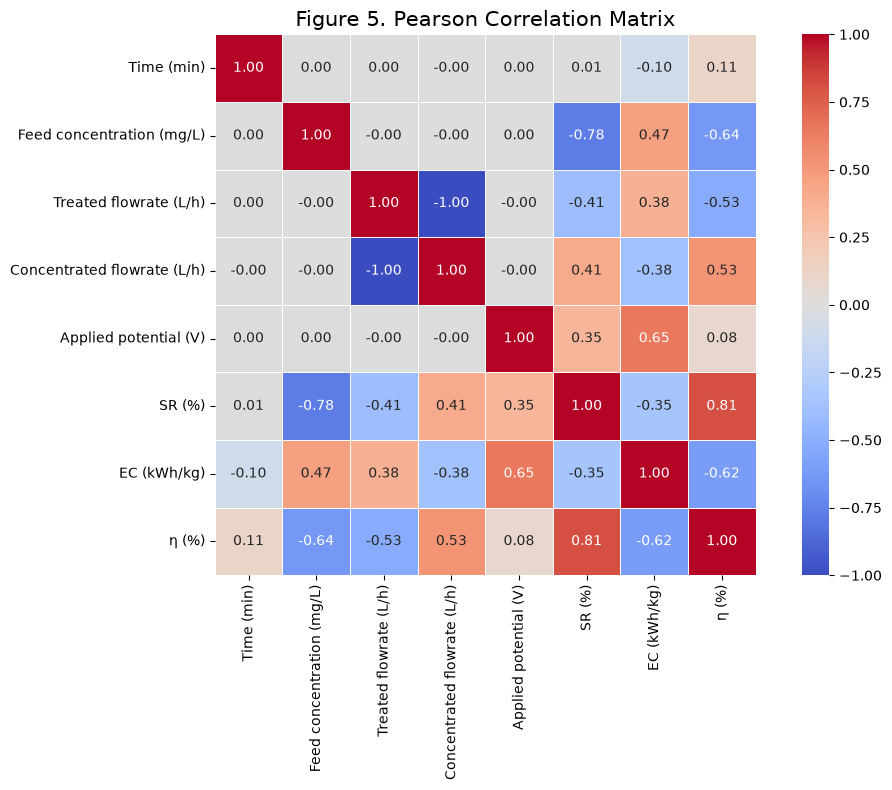

In [51]:
# ============================================================
# CELL 45 - FIGURE 5
# PEARSON CORRELATION MATRIX
# ============================================================

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title(
    "Figure 5. Pearson Correlation Matrix",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "Figure_5_Pearson_Correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [52]:
# ============================================================
# CELL 46 - MLR PREDICTIONS
# ============================================================

mlr_predictions = []

for i, target in enumerate(target_columns):

    model = LinearRegression()

    model.fit(
        X_train,
        y_train.iloc[:, i]
    )

    prediction = model.predict(
        X_test
    )

    mlr_predictions.append(prediction)

mlr_predictions = np.column_stack(
    mlr_predictions
)

mlr_results = evaluate_model(
    "MLR",
    y_test.values,
    mlr_predictions
)

display(mlr_results)

,Model,Target,R2,MSE,RMSE,MAE
0,MLR,SR (%),0.892896,37.438196,6.118676,4.663693
1,MLR,EC (kWh/kg),0.707652,0.120273,0.346804,0.278011
2,MLR,η (%),0.713249,44.339350,6.658780,5.068561


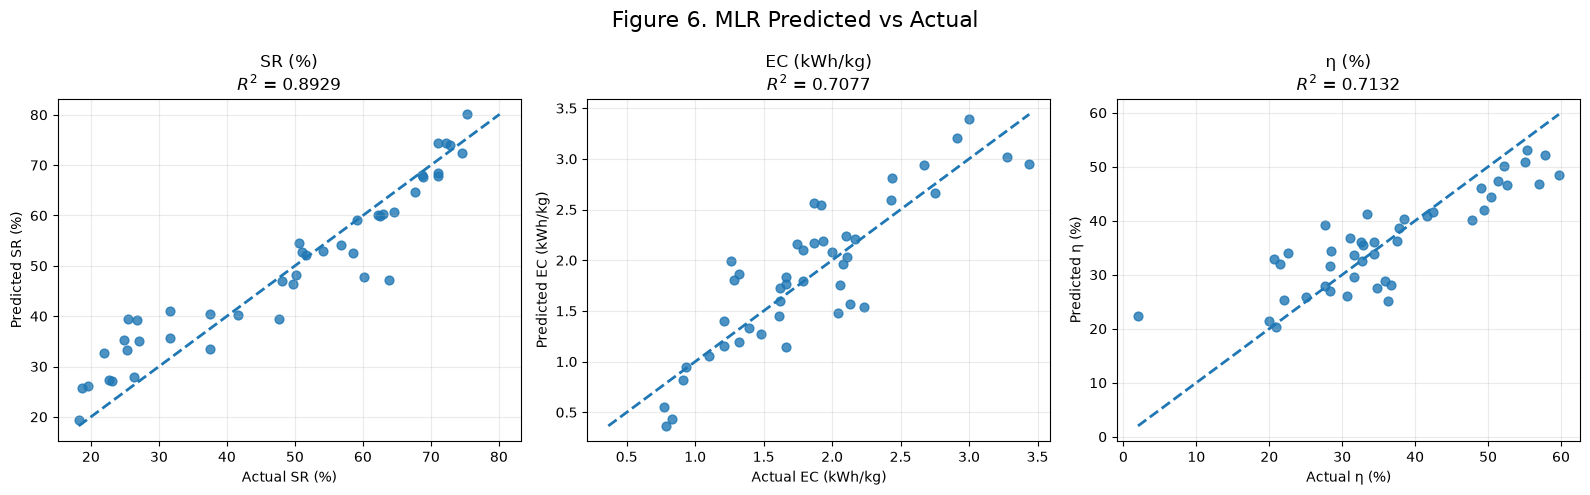

In [53]:
# ============================================================
# CELL 47 - FIGURE 6
# MLR ACTUAL VS PREDICTED
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

for i, target in enumerate(target_columns):

    ax = axes[i]

    actual = y_test.values[:, i]
    predicted = mlr_predictions[:, i]

    ax.scatter(
        actual,
        predicted,
        s=40,
        alpha=0.8
    )

    minimum = min(
        actual.min(),
        predicted.min()
    )

    maximum = max(
        actual.max(),
        predicted.max()
    )

    ax.plot(
        [minimum, maximum],
        [minimum, maximum],
        linestyle="--",
        linewidth=2
    )

    r2 = r2_score(
        actual,
        predicted
    )

    ax.set_title(
        f"{target}\n$R^2$ = {r2:.4f}"
    )

    ax.set_xlabel(
        f"Actual {target}"
    )

    ax.set_ylabel(
        f"Predicted {target}"
    )

    ax.grid(alpha=0.25)

fig.suptitle(
    "Figure 6. MLR Predicted vs Actual",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "Figure_6_MLR.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [54]:
# ============================================================
# CELL 48 - PAPER MLP TRAINING PREDICTIONS
# ============================================================

paper_mlp_train_predictions = []
paper_mlp_test_predictions = []

paper_mlp_models = []

for i, target in enumerate(target_columns):

    neurons = paper_neurons[target]

    model = MLPRegressor(
        hidden_layer_sizes=(neurons,),
        activation="tanh",
        solver="lbfgs",
        max_iter=2000,
        random_state=1
    )

    model.fit(
        X_train_scaled,
        y_train_scaled[:, i]
    )

    train_pred = model.predict(
        X_train_scaled
    )

    test_pred = model.predict(
        X_test_scaled
    )

    paper_mlp_models.append(model)

    paper_mlp_train_predictions.append(
        train_pred
    )

    paper_mlp_test_predictions.append(
        test_pred
    )

paper_mlp_train_predictions = np.column_stack(
    paper_mlp_train_predictions
)

paper_mlp_test_predictions = np.column_stack(
    paper_mlp_test_predictions
)

paper_mlp_train_original = y_scaler.inverse_transform(
    paper_mlp_train_predictions
)

paper_mlp_test_original = y_scaler.inverse_transform(
    paper_mlp_test_predictions
)

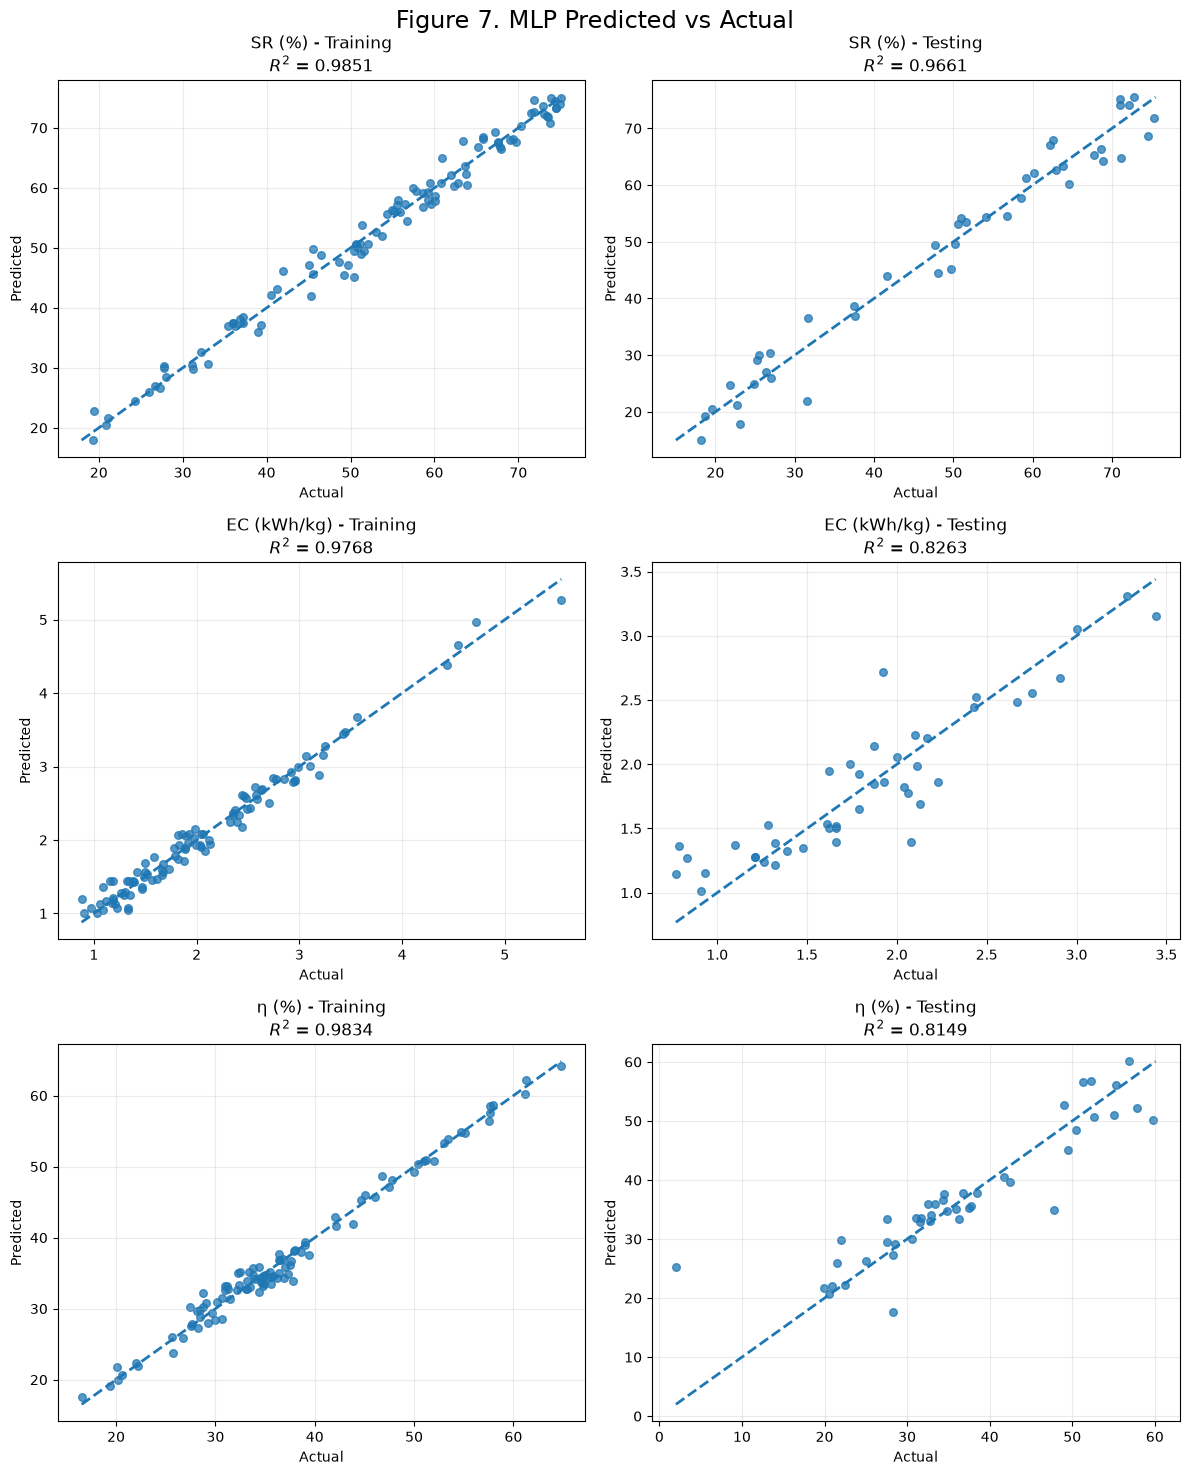

In [55]:
# ============================================================
# CELL 49 - FIGURE 7
# PAPER MLP ACTUAL VS PREDICTED
# ============================================================

fig, axes = plt.subplots(
    3,
    2,
    figsize=(12, 15)
)

for i, target in enumerate(target_columns):

    # Training
    ax = axes[i, 0]

    actual = y_train.values[:, i]
    predicted = paper_mlp_train_original[:, i]

    ax.scatter(
        actual,
        predicted,
        s=30,
        alpha=0.75
    )

    minimum = min(
        actual.min(),
        predicted.min()
    )

    maximum = max(
        actual.max(),
        predicted.max()
    )

    ax.plot(
        [minimum, maximum],
        [minimum, maximum],
        "--",
        linewidth=2
    )

    r2 = r2_score(
        y_train_scaled[:, i],
        paper_mlp_train_predictions[:, i]
    )

    ax.set_title(
        f"{target} - Training\n$R^2$ = {r2:.4f}"
    )

    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
    ax.grid(alpha=0.25)

    # Testing
    ax = axes[i, 1]

    actual = y_test.values[:, i]
    predicted = paper_mlp_test_original[:, i]

    ax.scatter(
        actual,
        predicted,
        s=30,
        alpha=0.75
    )

    minimum = min(
        actual.min(),
        predicted.min()
    )

    maximum = max(
        actual.max(),
        predicted.max()
    )

    ax.plot(
        [minimum, maximum],
        [minimum, maximum],
        "--",
        linewidth=2
    )

    r2 = r2_score(
        y_test_scaled[:, i],
        paper_mlp_test_predictions[:, i]
    )

    ax.set_title(
        f"{target} - Testing\n$R^2$ = {r2:.4f}"
    )

    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
    ax.grid(alpha=0.25)

fig.suptitle(
    "Figure 7. MLP Predicted vs Actual",
    fontsize=17
)

plt.tight_layout()

plt.savefig(
    "Figure_7_MLP.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

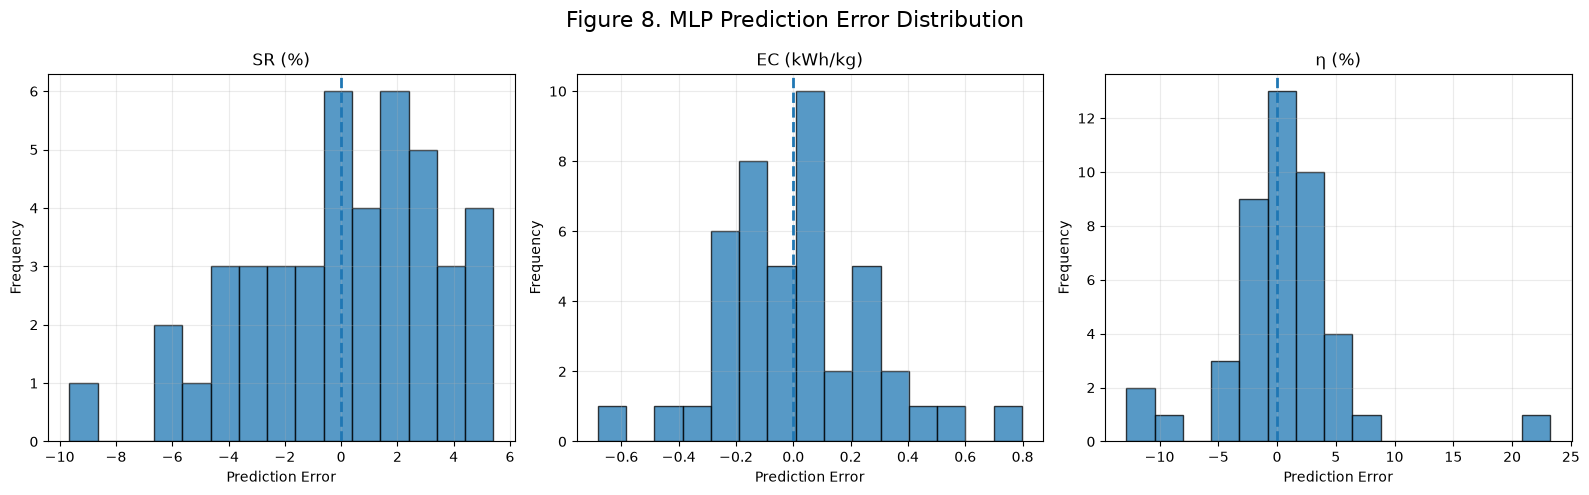

In [56]:
# ============================================================
# CELL 50 - FIGURE 8
# MLP ERROR DISTRIBUTION
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5)
)

for i, target in enumerate(target_columns):

    errors = (
        paper_mlp_test_original[:, i]
        -
        y_test.values[:, i]
    )

    axes[i].hist(
        errors,
        bins=15,
        edgecolor="black",
        alpha=0.75
    )

    axes[i].axvline(
        0,
        linestyle="--",
        linewidth=2
    )

    axes[i].set_title(
        target
    )

    axes[i].set_xlabel(
        "Prediction Error"
    )

    axes[i].set_ylabel(
        "Frequency"
    )

    axes[i].grid(alpha=0.25)

fig.suptitle(
    "Figure 8. MLP Prediction Error Distribution",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "Figure_8_MLP_Error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [57]:
pip install numpy==2.4.5

Note: you may need to restart the kernel to use updated packages.



SHAP: SR (%)


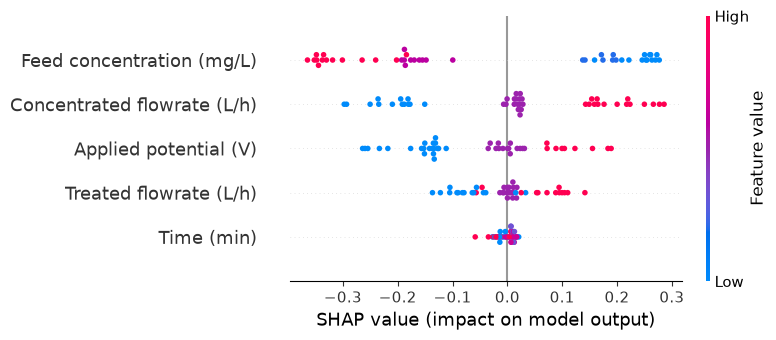


SHAP: EC (kWh/kg)


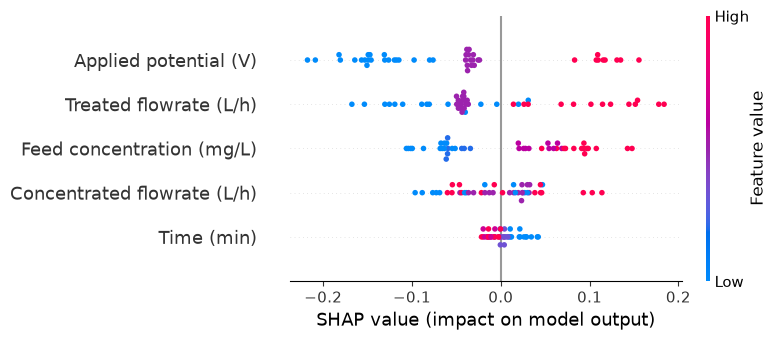


SHAP: η (%)


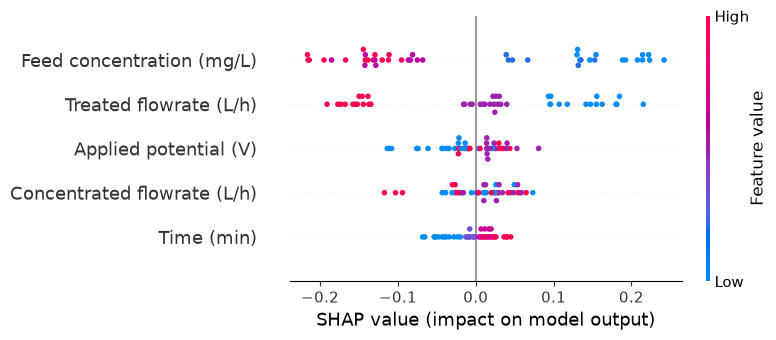

In [58]:
# ============================================================
# CELL 51 - MLP SHAP
# ============================================================

import shap

for i, target in enumerate(target_columns):

    print("\nSHAP:", target)

    explainer = shap.Explainer(
        paper_mlp_models[i].predict,
        X_train_scaled
    )

    shap_values = explainer(
        X_test_scaled
    )

    shap.summary_plot(
        shap_values,
        X_test_scaled,
        feature_names=feature_columns,
        show=True
    )

In [59]:
# ============================================================
# CELL 52 - PAPER RANDOM FOREST
# ============================================================

paper_rf_trees = {
    "SR (%)": 50,
    "EC (kWh/kg)": 30,
    "η (%)": 100
}

paper_rf_models = []

paper_rf_train_predictions = []
paper_rf_test_predictions = []

for i, target in enumerate(target_columns):

    model = RandomForestRegressor(
        n_estimators=paper_rf_trees[target],
        random_state=2,
        max_features=1.0,
        n_jobs=-1
    )

    model.fit(
        X_train_scaled,
        y_train_scaled[:, i]
    )

    train_pred = model.predict(
        X_train_scaled
    )

    test_pred = model.predict(
        X_test_scaled
    )

    paper_rf_models.append(model)

    paper_rf_train_predictions.append(
        train_pred
    )

    paper_rf_test_predictions.append(
        test_pred
    )

paper_rf_train_predictions = np.column_stack(
    paper_rf_train_predictions
)

paper_rf_test_predictions = np.column_stack(
    paper_rf_test_predictions
)

paper_rf_train_original = y_scaler.inverse_transform(
    paper_rf_train_predictions
)

paper_rf_test_original = y_scaler.inverse_transform(
    paper_rf_test_predictions
)

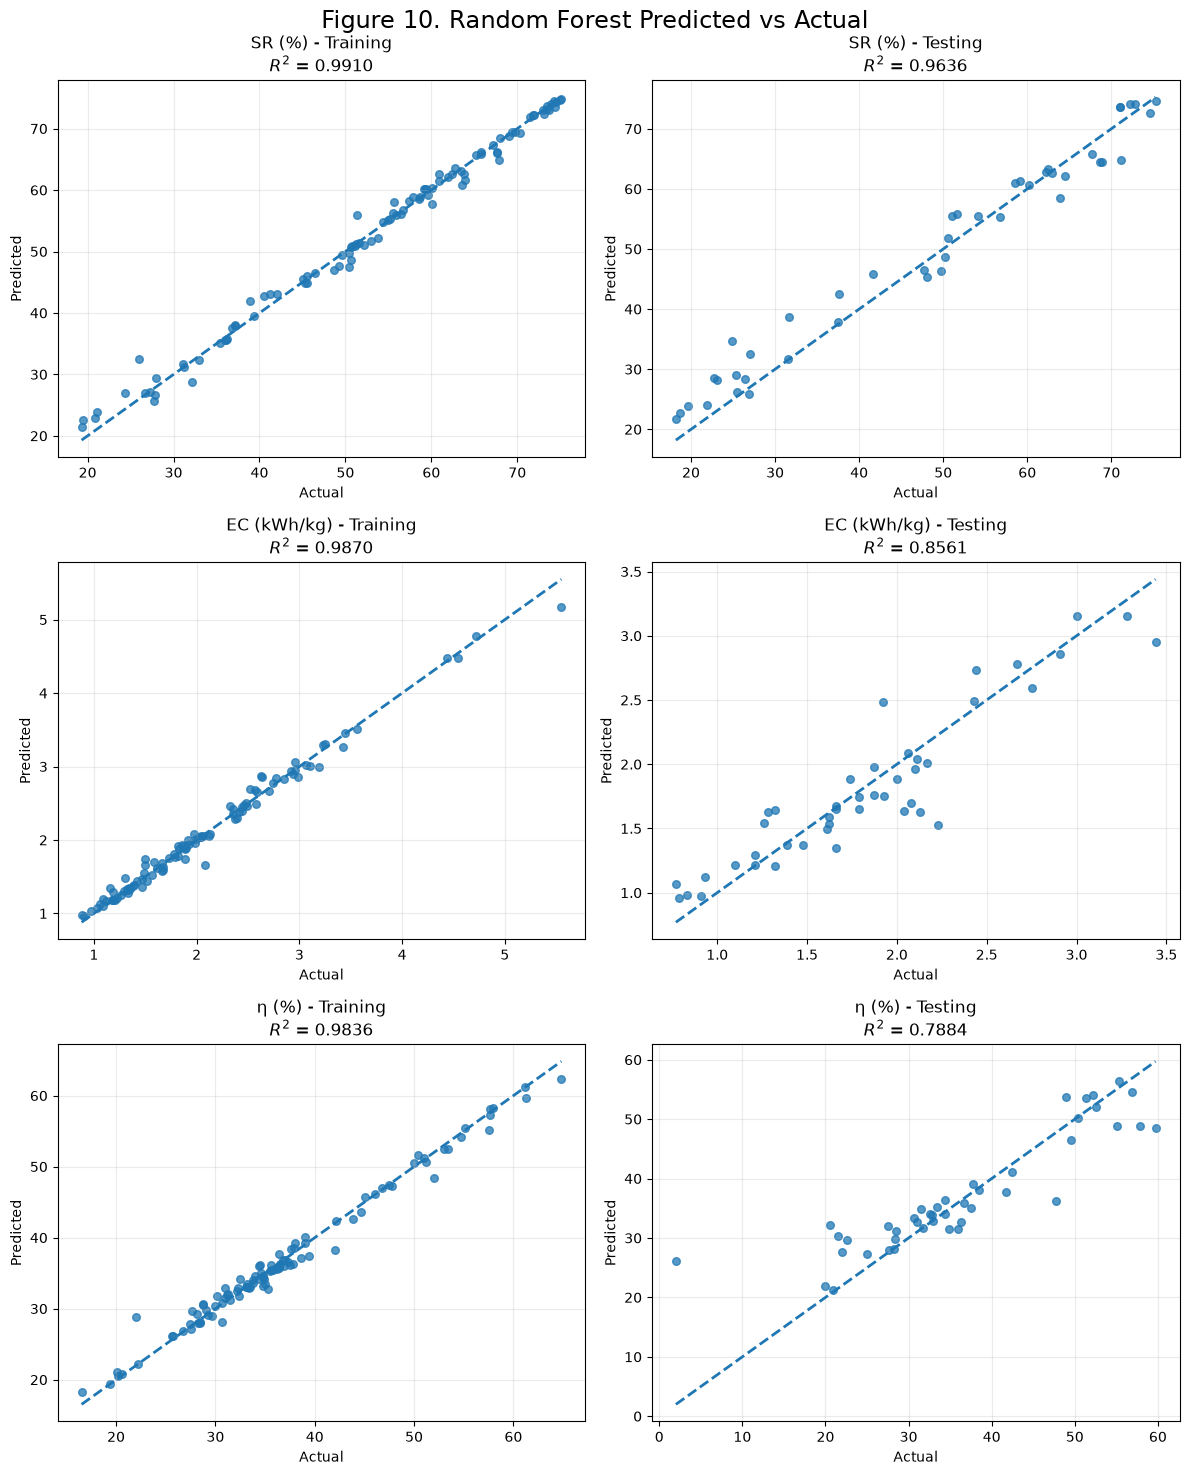

In [60]:
# ============================================================
# CELL 53 - FIGURE 10
# PAPER RF ACTUAL VS PREDICTED
# ============================================================

fig, axes = plt.subplots(
    3,
    2,
    figsize=(12, 15)
)

for i, target in enumerate(target_columns):

    # Training
    ax = axes[i, 0]

    actual = y_train.values[:, i]
    predicted = paper_rf_train_original[:, i]

    ax.scatter(
        actual,
        predicted,
        s=30,
        alpha=0.75
    )

    low = min(
        actual.min(),
        predicted.min()
    )

    high = max(
        actual.max(),
        predicted.max()
    )

    ax.plot(
        [low, high],
        [low, high],
        "--",
        linewidth=2
    )

    r2 = r2_score(
        y_train_scaled[:, i],
        paper_rf_train_predictions[:, i]
    )

    ax.set_title(
        f"{target} - Training\n$R^2$ = {r2:.4f}"
    )

    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
    ax.grid(alpha=0.25)

    # Testing
    ax = axes[i, 1]

    actual = y_test.values[:, i]
    predicted = paper_rf_test_original[:, i]

    ax.scatter(
        actual,
        predicted,
        s=30,
        alpha=0.75
    )

    low = min(
        actual.min(),
        predicted.min()
    )

    high = max(
        actual.max(),
        predicted.max()
    )

    ax.plot(
        [low, high],
        [low, high],
        "--",
        linewidth=2
    )

    r2 = r2_score(
        y_test_scaled[:, i],
        paper_rf_test_predictions[:, i]
    )

    ax.set_title(
        f"{target} - Testing\n$R^2$ = {r2:.4f}"
    )

    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
    ax.grid(alpha=0.25)

fig.suptitle(
    "Figure 10. Random Forest Predicted vs Actual",
    fontsize=17
)

plt.tight_layout()

plt.savefig(
    "Figure_10_RF.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

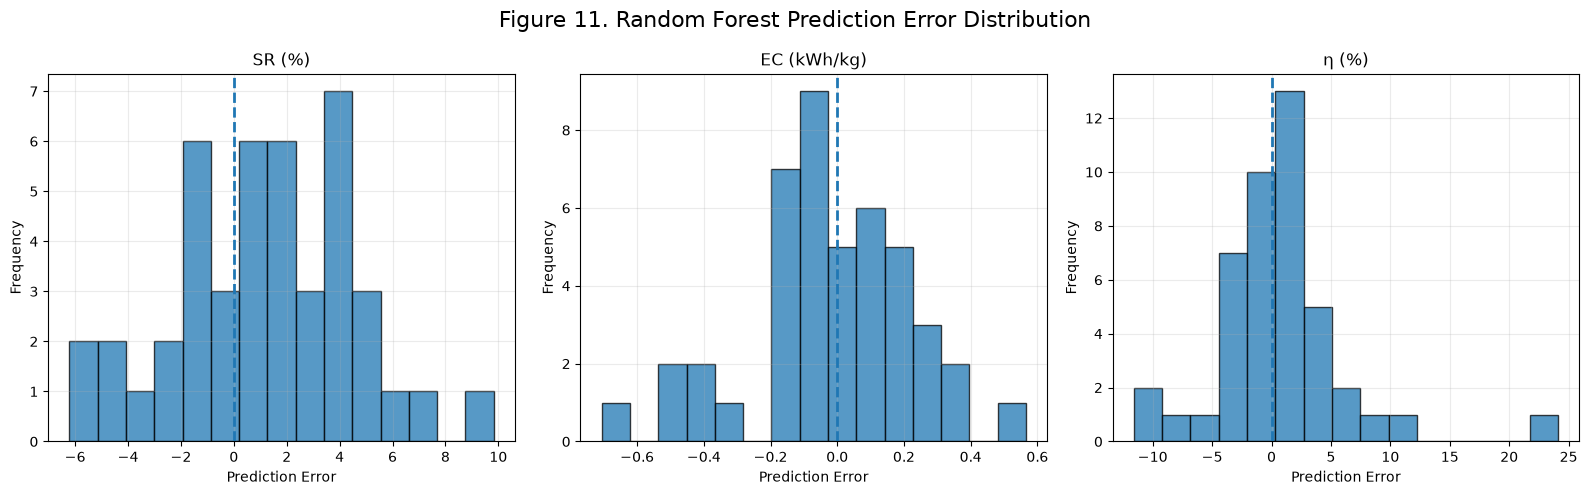

In [61]:
# ============================================================
# CELL 54 - FIGURE 11
# RF ERROR DISTRIBUTION
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5)
)

for i, target in enumerate(target_columns):

    errors = (
        paper_rf_test_original[:, i]
        -
        y_test.values[:, i]
    )

    axes[i].hist(
        errors,
        bins=15,
        edgecolor="black",
        alpha=0.75
    )

    axes[i].axvline(
        0,
        linestyle="--",
        linewidth=2
    )

    axes[i].set_title(target)

    axes[i].set_xlabel(
        "Prediction Error"
    )

    axes[i].set_ylabel(
        "Frequency"
    )

    axes[i].grid(alpha=0.25)

fig.suptitle(
    "Figure 11. Random Forest Prediction Error Distribution",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "Figure_11_RF_Error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


SHAP: SR (%)


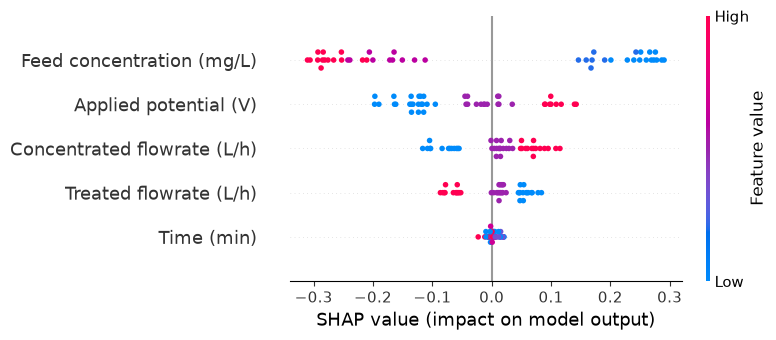


SHAP: EC (kWh/kg)


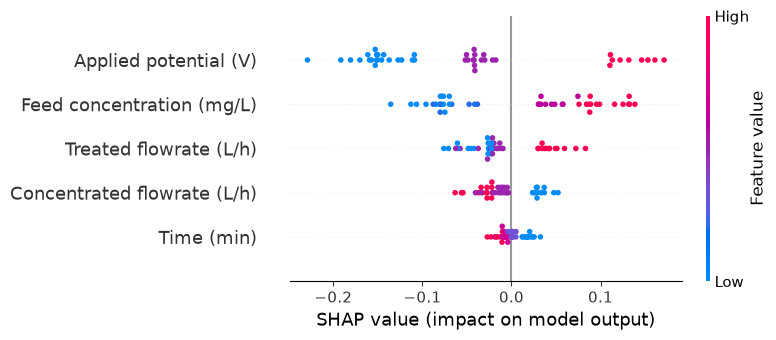


SHAP: η (%)


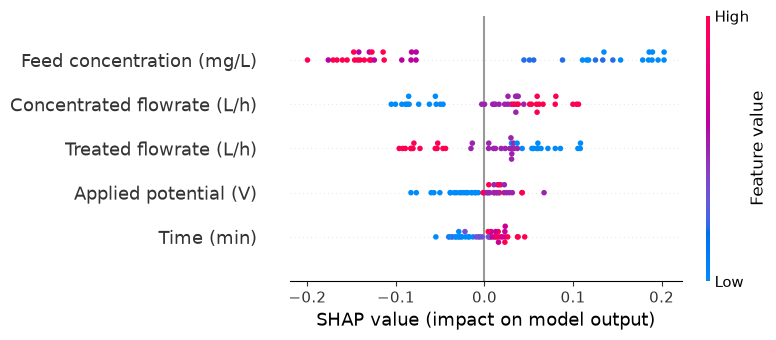

In [62]:
# ============================================================
# CELL 55 - RF SHAP
# ============================================================

for i, target in enumerate(target_columns):

    print("\nSHAP:", target)

    explainer = shap.TreeExplainer(
        paper_rf_models[i]
    )

    shap_values = explainer.shap_values(
        X_test_scaled
    )

    shap.summary_plot(
        shap_values,
        X_test_scaled,
        feature_names=feature_columns,
        show=True
    )

In [78]:
# ============================================================
# CELL 56 - FIGURE 13
# PAPER-STYLE MLP EXPERIMENTAL VS PREDICTED
# ============================================================

# Predict all 144 experimental observations
all_X_scaled = X_scaler.transform(X)

mlp_all_predictions = []

for model in paper_mlp_models:

    pred = model.predict(
        all_X_scaled
    )

    mlp_all_predictions.append(pred)

mlp_all_predictions = np.column_stack(
    mlp_all_predictions
)

# Convert predictions back to original units
mlp_all_original = y_scaler.inverse_transform(
    mlp_all_predictions
)

# Experimental values
experimental = y.values

# Experiment numbers
experiment_number = np.arange(
    1,
    len(df) + 1
)

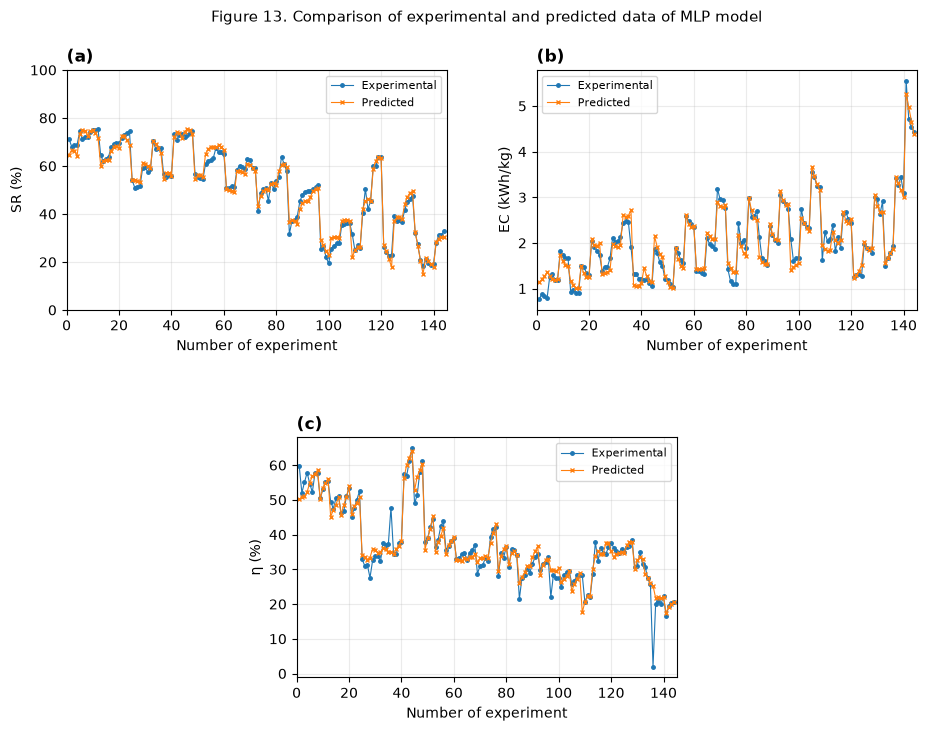

In [79]:
# ============================================================
# CELL 57 - PAPER FIGURE 13 STYLE
# ============================================================

fig = plt.figure(
    figsize=(10, 7.5)
)

# ------------------------------------------------------------
# (a) SALT REMOVAL
# ------------------------------------------------------------

ax1 = fig.add_axes(
    [0.08, 0.57, 0.38, 0.32]
)

ax1.plot(
    experiment_number,
    experimental[:, 0],
    marker="o",
    markersize=2.5,
    linewidth=0.8,
    label="Experimental"
)

ax1.plot(
    experiment_number,
    mlp_all_original[:, 0],
    marker="x",
    markersize=2.5,
    linewidth=0.8,
    label="Predicted"
)

ax1.set_title(
    "(a)",
    loc="left",
    fontweight="bold"
)

ax1.set_xlabel(
    "Number of experiment"
)

ax1.set_ylabel(
    "SR (%)"
)

ax1.set_xlim(
    0,
    145
)

ax1.set_ylim(
    0,
    100
)

ax1.grid(
    alpha=0.25
)

ax1.legend(
    fontsize=8
)


# ------------------------------------------------------------
# (b) ENERGY CONSUMPTION
# ------------------------------------------------------------

ax2 = fig.add_axes(
    [0.55, 0.57, 0.38, 0.32]
)

ax2.plot(
    experiment_number,
    experimental[:, 1],
    marker="o",
    markersize=2.5,
    linewidth=0.8,
    label="Experimental"
)

ax2.plot(
    experiment_number,
    mlp_all_original[:, 1],
    marker="x",
    markersize=2.5,
    linewidth=0.8,
    label="Predicted"
)

ax2.set_title(
    "(b)",
    loc="left",
    fontweight="bold"
)

ax2.set_xlabel(
    "Number of experiment"
)

ax2.set_ylabel(
    "EC (kWh/kg)"
)

ax2.set_xlim(
    0,
    145
)

ax2.grid(
    alpha=0.25
)

ax2.legend(
    fontsize=8
)


# ------------------------------------------------------------
# (c) CURRENT EFFICIENCY
# ------------------------------------------------------------

ax3 = fig.add_axes(
    [0.31, 0.08, 0.38, 0.32]
)

ax3.plot(
    experiment_number,
    experimental[:, 2],
    marker="o",
    markersize=2.5,
    linewidth=0.8,
    label="Experimental"
)

ax3.plot(
    experiment_number,
    mlp_all_original[:, 2],
    marker="x",
    markersize=2.5,
    linewidth=0.8,
    label="Predicted"
)

ax3.set_title(
    "(c)",
    loc="left",
    fontweight="bold"
)

ax3.set_xlabel(
    "Number of experiment"
)

ax3.set_ylabel(
    "η (%)"
)

ax3.set_xlim(
    0,
    145
)

ax3.grid(
    alpha=0.25
)

ax3.legend(
    fontsize=8
)


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

fig.suptitle(
    "Figure 13. Comparison of experimental and predicted data of MLP model",
    fontsize=11,
    y=0.97
)

plt.savefig(
    "Figure_13_MLP_Paper_Style.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [80]:
# ============================================================
# CELL 58 - FULL-DATA MLP FOR FIGURE REPRODUCTION
# ============================================================

# Normalize the complete dataset
X_full_scaler = MinMaxScaler()
y_full_scaler = MinMaxScaler()

X_full_scaled = X_full_scaler.fit_transform(
    X
)

y_full_scaled = y_full_scaler.fit_transform(
    y
)


# Store full-data models
full_mlp_models = []

full_mlp_predictions = []

for i, target in enumerate(target_columns):

    neurons = paper_neurons[target]

    model = MLPRegressor(
        hidden_layer_sizes=(neurons,),
        activation="tanh",
        solver="lbfgs",
        max_iter=2000,
        random_state=1
    )

    model.fit(
        X_full_scaled,
        y_full_scaled[:, i]
    )

    prediction = model.predict(
        X_full_scaled
    )

    full_mlp_models.append(
        model
    )

    full_mlp_predictions.append(
        prediction
    )


full_mlp_predictions = np.column_stack(
    full_mlp_predictions
)

full_mlp_original = y_full_scaler.inverse_transform(
    full_mlp_predictions
)

In [81]:
# ============================================================
# CELL 59 - COMPARE 70% TRAINED VS FULL DATA
# ============================================================

for i, target in enumerate(target_columns):

    r2_70 = r2_score(
        y.values[:, i],
        mlp_all_original[:, i]
    )

    r2_full = r2_score(
        y.values[:, i],
        full_mlp_original[:, i]
    )

    print("\n", target)

    print(
        "70% trained model R²:",
        round(r2_70, 4)
    )

    print(
        "Full-data model R²:",
        round(r2_full, 4)
    )


 SR (%)
70% trained model R²: 0.978
Full-data model R²: 0.991

 EC (kWh/kg)
70% trained model R²: 0.949
Full-data model R²: 0.9627

 η (%)
70% trained model R²: 0.9164
Full-data model R²: 0.9708


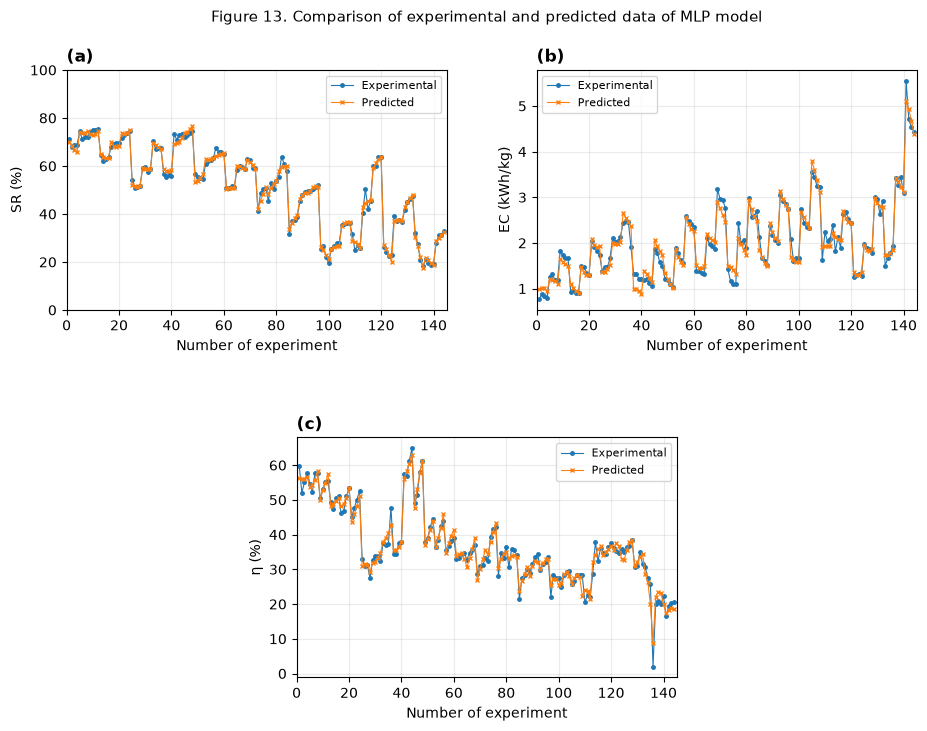

In [82]:
# ============================================================
# CELL 60 - FIGURE 13 USING FULL-DATA MLP
# ============================================================

fig = plt.figure(
    figsize=(10, 7.5)
)

# ------------------------------------------------------------
# (a) SR
# ------------------------------------------------------------

ax1 = fig.add_axes(
    [0.08, 0.57, 0.38, 0.32]
)

ax1.plot(
    experiment_number,
    experimental[:, 0],
    marker="o",
    markersize=2.5,
    linewidth=0.8,
    label="Experimental"
)

ax1.plot(
    experiment_number,
    full_mlp_original[:, 0],
    marker="x",
    markersize=2.5,
    linewidth=0.8,
    label="Predicted"
)

ax1.set_title(
    "(a)",
    loc="left",
    fontweight="bold"
)

ax1.set_xlabel("Number of experiment")
ax1.set_ylabel("SR (%)")

ax1.set_xlim(0, 145)
ax1.set_ylim(0, 100)

ax1.grid(alpha=0.25)
ax1.legend(fontsize=8)


# ------------------------------------------------------------
# (b) EC
# ------------------------------------------------------------

ax2 = fig.add_axes(
    [0.55, 0.57, 0.38, 0.32]
)

ax2.plot(
    experiment_number,
    experimental[:, 1],
    marker="o",
    markersize=2.5,
    linewidth=0.8,
    label="Experimental"
)

ax2.plot(
    experiment_number,
    full_mlp_original[:, 1],
    marker="x",
    markersize=2.5,
    linewidth=0.8,
    label="Predicted"
)

ax2.set_title(
    "(b)",
    loc="left",
    fontweight="bold"
)

ax2.set_xlabel("Number of experiment")
ax2.set_ylabel("EC (kWh/kg)")

ax2.set_xlim(0, 145)

ax2.grid(alpha=0.25)
ax2.legend(fontsize=8)


# ------------------------------------------------------------
# (c) η
# ------------------------------------------------------------

ax3 = fig.add_axes(
    [0.31, 0.08, 0.38, 0.32]
)

ax3.plot(
    experiment_number,
    experimental[:, 2],
    marker="o",
    markersize=2.5,
    linewidth=0.8,
    label="Experimental"
)

ax3.plot(
    experiment_number,
    full_mlp_original[:, 2],
    marker="x",
    markersize=2.5,
    linewidth=0.8,
    label="Predicted"
)

ax3.set_title(
    "(c)",
    loc="left",
    fontweight="bold"
)

ax3.set_xlabel("Number of experiment")
ax3.set_ylabel("η (%)")

ax3.set_xlim(0, 145)

ax3.grid(alpha=0.25)
ax3.legend(fontsize=8)


fig.suptitle(
    "Figure 13. Comparison of experimental and predicted data of MLP model",
    fontsize=11,
    y=0.97
)

plt.savefig(
    "Figure_13_MLP_Replication.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

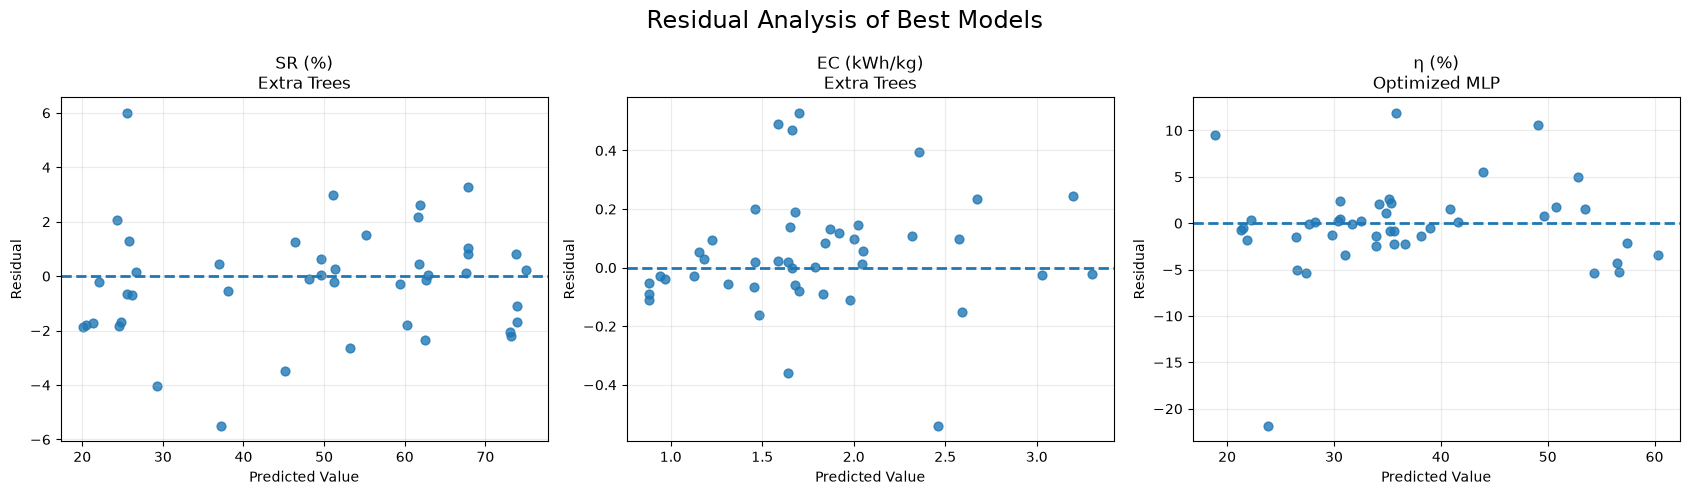

In [68]:
# ============================================================
# CELL 61 - RESIDUAL PLOTS
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)

for i, target in enumerate(target_columns):

    actual = y_test.values[:, i]

    predicted = best_predictions[:, i]

    residuals = actual - predicted

    axes[i].scatter(
        predicted,
        residuals,
        s=40,
        alpha=0.8
    )

    axes[i].axhline(
        0,
        linestyle="--",
        linewidth=2
    )

    axes[i].set_title(
        f"{target}\n{best_model_names[i]}"
    )

    axes[i].set_xlabel(
        "Predicted Value"
    )

    axes[i].set_ylabel(
        "Residual"
    )

    axes[i].grid(alpha=0.25)

fig.suptitle(
    "Residual Analysis of Best Models",
    fontsize=17
)

plt.tight_layout()

plt.savefig(
    "Best_Model_Residuals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

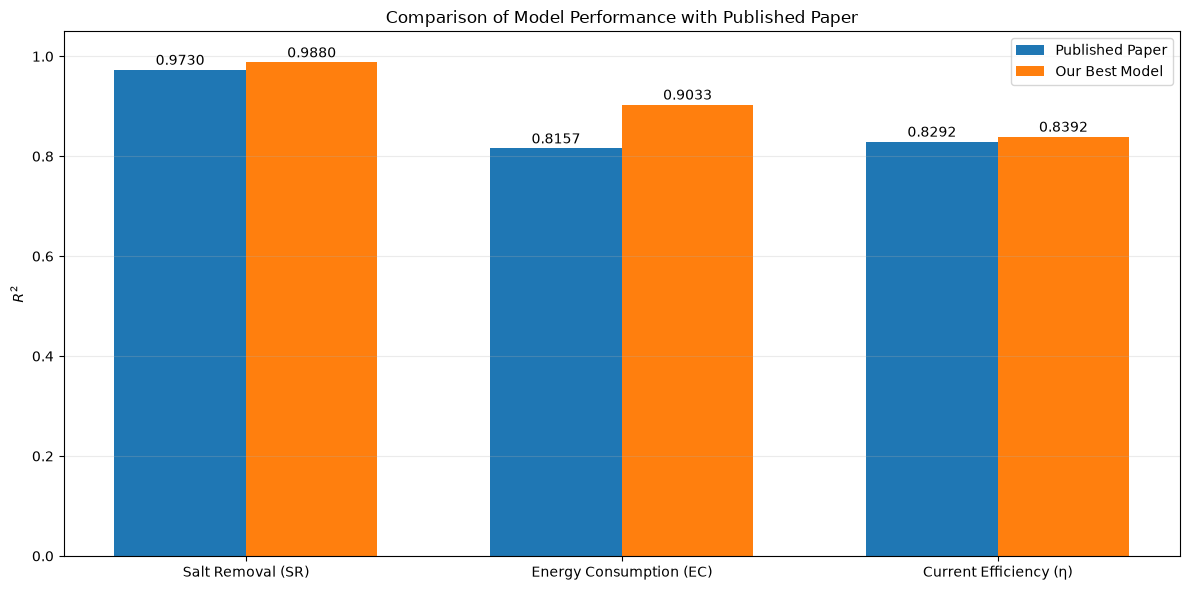

In [69]:
# ============================================================
# CELL 62 - PAPER VS OUR MODEL R2
# ============================================================

x = np.arange(
    len(target_columns)
)

width = 0.35

paper_r2 = [
    0.9730,
    0.8157,
    0.8292
]

our_r2 = [
    0.987967,
    0.903338,
    0.839171
]

fig, ax = plt.subplots(
    figsize=(12, 6)
)

bars1 = ax.bar(
    x - width/2,
    paper_r2,
    width,
    label="Published Paper"
)

bars2 = ax.bar(
    x + width/2,
    our_r2,
    width,
    label="Our Best Model"
)

ax.set_ylabel(
    "$R^2$"
)

ax.set_title(
    "Comparison of Model Performance with Published Paper"
)

ax.set_xticks(x)

ax.set_xticklabels([
    "Salt Removal (SR)",
    "Energy Consumption (EC)",
    "Current Efficiency (η)"
])

ax.set_ylim(
    0,
    1.05
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.25
)

for bars in [bars1, bars2]:

    for bar in bars:

        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.01,
            f"{height:.4f}",
            ha="center",
            fontsize=10
        )

plt.tight_layout()

plt.savefig(
    "Paper_vs_Our_R2_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

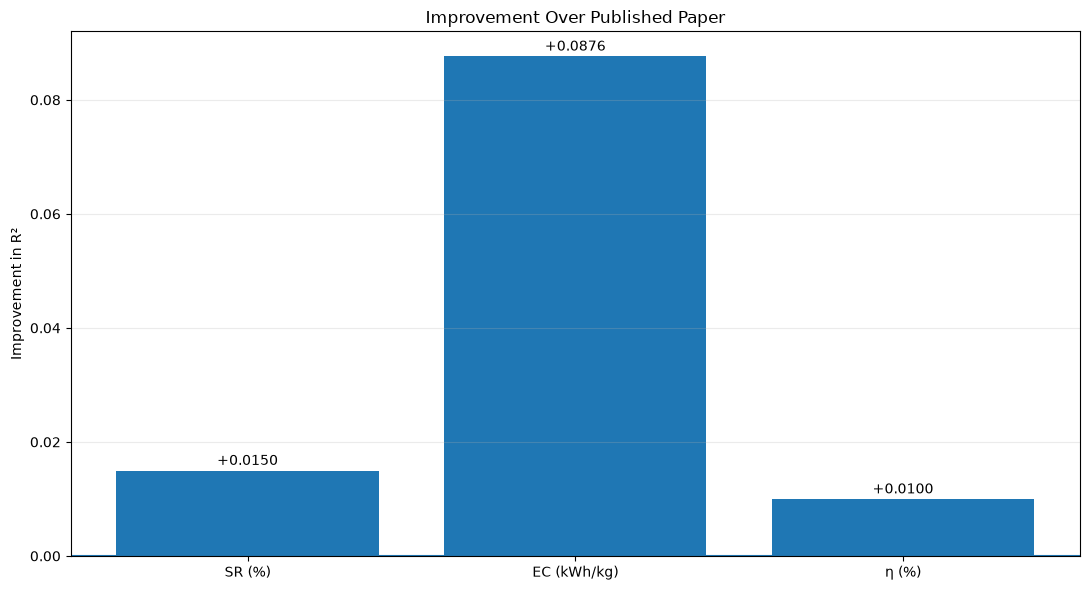

In [70]:
# ============================================================
# CELL 63 - R2 IMPROVEMENT
# ============================================================

improvements = (
    np.array(our_r2)
    -
    np.array(paper_r2)
)

fig, ax = plt.subplots(
    figsize=(11, 6)
)

bars = ax.bar(
    target_columns,
    improvements
)

ax.axhline(
    0,
    linewidth=1.5
)

ax.set_ylabel(
    "Improvement in R²"
)

ax.set_title(
    "Improvement Over Published Paper"
)

ax.grid(
    axis="y",
    alpha=0.25
)

for bar, value in zip(
    bars,
    improvements
):

    ax.text(
        bar.get_x() +
        bar.get_width()/2,
        value + 0.001,
        f"+{value:.4f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "R2_Improvement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [71]:
# ============================================================
# CELL 64 - FINAL COMPARISON TABLE
# ============================================================

final_comparison = pd.DataFrame({

    "Output": [
        "Salt Removal",
        "Energy Consumption",
        "Current Efficiency"
    ],

    "Paper Model": [
        "MLP",
        "MLP",
        "MLP"
    ],

    "Paper R2": [
        0.9730,
        0.8157,
        0.8292
    ],

    "Our Best Model": [
        "Extra Trees",
        "Extra Trees",
        "Optimized MLP"
    ],

    "Our R2": [
        0.987967,
        0.903338,
        0.839171
    ]
})

final_comparison["R2 Improvement"] = (
    final_comparison["Our R2"]
    -
    final_comparison["Paper R2"]
)

display(final_comparison)

,Output,Paper Model,Paper R2,Our Best Model,Our R2,R2 Improvement
0,Salt Removal,MLP,0.9730,Extra Trees,0.987967,0.014967
1,Energy Consumption,MLP,0.8157,Extra Trees,0.903338,0.087638
2,Current Efficiency,MLP,0.8292,Optimized MLP,0.839171,0.009971


In [72]:
# ============================================================
# CELL 65 - SAVE FINAL TABLES
# ============================================================

final_comparison.to_csv(
    "Final_Paper_vs_Our_Comparison.csv",
    index=False
)

final_results.to_csv(
    "All_Model_Results.csv",
    index=False
)

best_models.to_csv(
    "Best_Models.csv",
    index=False
)

print("All result tables saved.")

All result tables saved.



SHAP: SR (%)


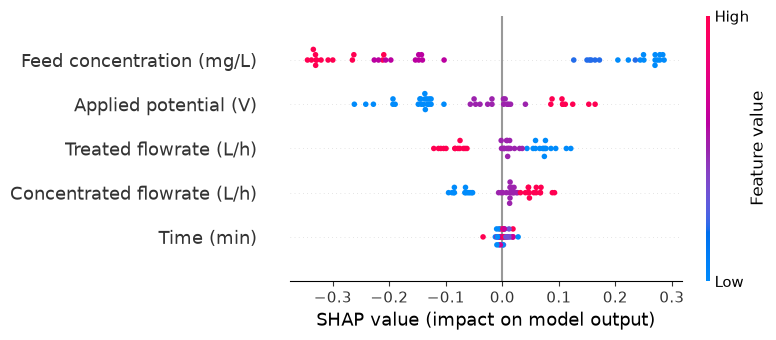


SHAP: EC (kWh/kg)


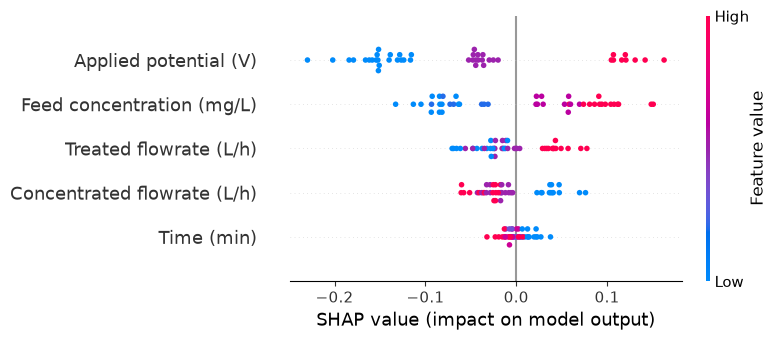


SHAP: η (%)


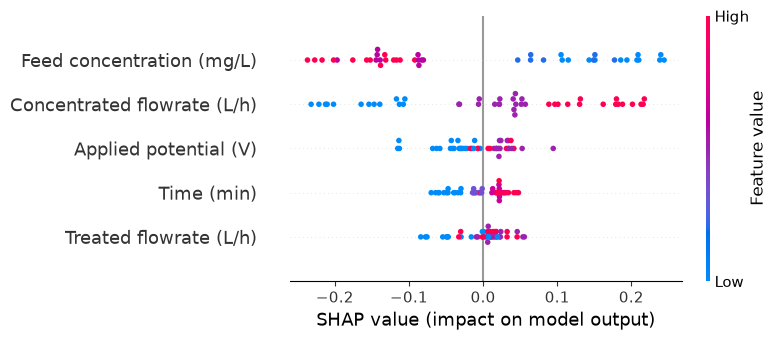

In [73]:
# ============================================================
# CELL 66 - BEST MODEL SHAP
# ============================================================

import shap

best_models_list = [
    extra_trees_models[0],
    extra_trees_models[1],
    optimized_mlp_models[2]
]

best_model_targets = [
    "SR (%)",
    "EC (kWh/kg)",
    "η (%)"
]

for model, target in zip(
    best_models_list,
    best_model_targets
):

    print("\nSHAP:", target)

    if isinstance(
        model,
        ExtraTreesRegressor
    ):

        explainer = shap.TreeExplainer(
            model
        )

    else:

        explainer = shap.Explainer(
            model.predict,
            X_train_scaled
        )

    shap_values = explainer(
        X_test_scaled
    )

    shap.summary_plot(
        shap_values,
        X_test_scaled,
        feature_names=feature_columns,
        show=True
    )

In [75]:
from sklearn.inspection import permutation_importance

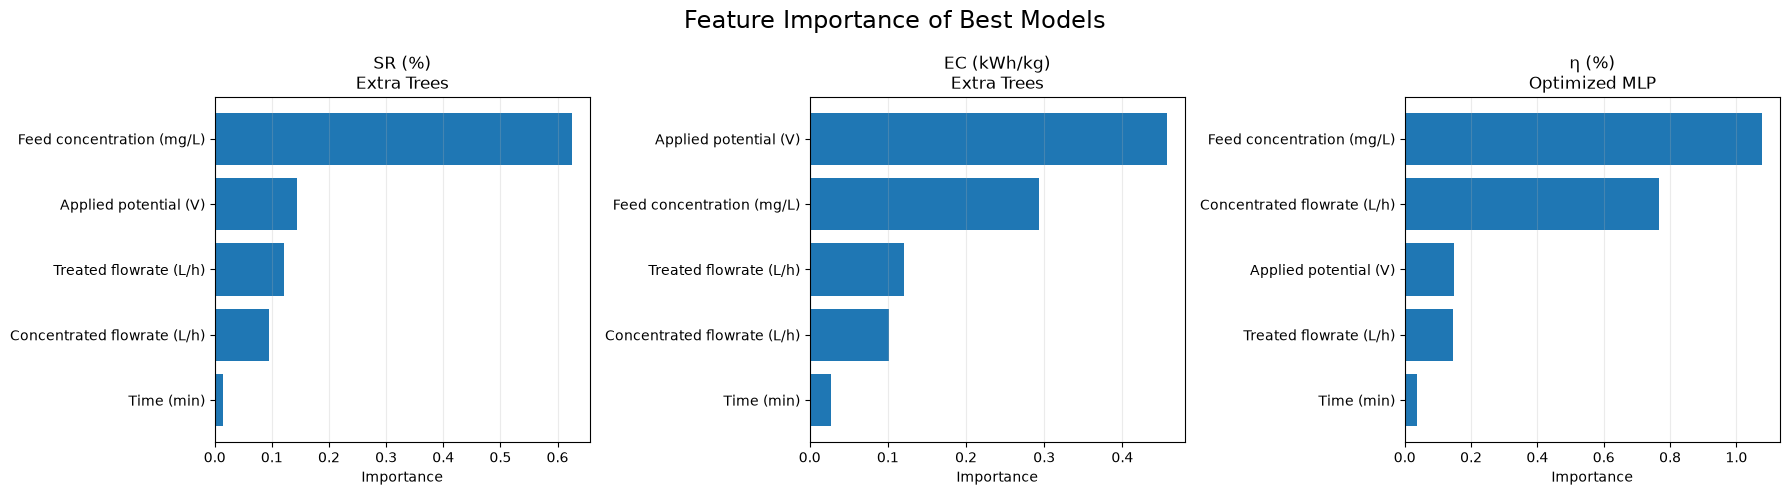

In [76]:
# ============================================================
# CELL 67 - FEATURE IMPORTANCE
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

for i, target in enumerate(
    best_model_targets
):

    model = best_models_list[i]

    if hasattr(
        model,
        "feature_importances_"
    ):

        importance = (
            model.feature_importances_
        )

    else:

        permutation = permutation_importance(
            model,
            X_test_scaled,
            y_test_scaled[:, i],
            n_repeats=30,
            random_state=42,
            scoring="r2"
        )

        importance = (
            permutation.importances_mean
        )

    order = np.argsort(
        importance
    )

    axes[i].barh(
        np.array(feature_columns)[order],
        importance[order]
    )

    axes[i].set_title(
        f"{target}\n{best_model_names[i]}"
    )

    axes[i].set_xlabel(
        "Importance"
    )

    axes[i].grid(
        axis="x",
        alpha=0.25
    )

fig.suptitle(
    "Feature Importance of Best Models",
    fontsize=17
)

plt.tight_layout()

plt.savefig(
    "Best_Model_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [77]:
# ============================================================
# CELL 68 - FINAL SUMMARY
# ============================================================

print("=" * 70)
print("FINAL PAPER REPLICATION + IMPROVEMENT RESULTS")
print("=" * 70)

for i, target in enumerate(target_columns):

    paper_score = paper_r2[i]
    our_score = our_r2[i]

    print("\nTarget:", target)
    print("Paper R² :", round(paper_score, 6))
    print("Our R²   :", round(our_score, 6))
    print("Model    :", best_model_names[i])
    print("Gain     :", round(our_score - paper_score, 6))

print("\n" + "=" * 70)

FINAL PAPER REPLICATION + IMPROVEMENT RESULTS

Target: SR (%)
Paper R² : 0.973
Our R²   : 0.987967
Model    : Extra Trees
Gain     : 0.014967

Target: EC (kWh/kg)
Paper R² : 0.8157
Our R²   : 0.903338
Model    : Extra Trees
Gain     : 0.087638

Target: η (%)
Paper R² : 0.8292
Our R²   : 0.839171
Model    : Optimized MLP
Gain     : 0.009971

